# 11A. Baseline Metric Visualizations

**Companion Visualization Notebook for Baseline Model Evaluation (Notebook 11)**

This notebook ingests the verified experimental results produced by `11_BACKUP(3).ipynb` and generates publication-grade visualizations across all baseline architectures and preprocessing branches:

1. **Figure Type 1:** Training Loss and Validation Loss vs. Epochs (2×2 subplots per deep model)
2. **Figure Type 2:** Training Accuracy and Validation Accuracy vs. Epochs (2×2 subplots per deep model, 0–1 scale)
3. **Figure Type 3:** Held-Out Test Confusion Matrices with Raw Counts and Row Percentages (2×2 subplots per model, all 5 models)

**Architectures Evaluated:**
- `CNN1D`
- `LSTM`
- `BiLSTM`
- `BiLSTM_CNN`
- `Classical_LR` (Confusion Matrices only; no epoch history recorded)

**Preprocessing Branches:**
- `gsn_minmax`: Global Sequence Normalization + Sequence-wise MinMax Scaling
- `gsn_zscore`: Global Sequence Normalization + Sequence-wise Z-Score Standardization
- `tbsn_minmax`: Trend-Based Sequence Normalization + Channel-wise MinMax Scaling
- `tbsn_zscore`: Trend-Based Sequence Normalization + Channel-wise Z-Score Standardization

**Target Classes:**
- `Class 0`: UPDRS-III walking score 0
- `Class 1`: UPDRS-III walking score 1
- `Class 2`: UPDRS-III walking score 2

**Evaluation Partition:**
- `trial_split`: Authoritative 70% TRAIN / 15% VALIDATION / 15% TEST split (131 held-out test trials per branch).

---
## 1. Setup, Environment, and Publication Styling

Resolve the project root dynamically by discovering `configs/`, `src/`, and `results/`. Set up deterministic figure directories and publication-quality Matplotlib configurations.

In [1]:
# ============================================================================
# CELL 1: SETUP, ROOT RESOLUTION, DIRECTORIES, AND STYLING
# ============================================================================
import os, sys, json, tempfile
from pathlib import Path
import numpy as np
import pandas as pd

# Direct matplotlib cache to writable temporary directory
os.environ['MPLCONFIGDIR'] = str(tempfile.gettempdir())

import matplotlib
matplotlib.use('Agg')  # Headless backend; inline display handled via plt.show()
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Dynamic Project Root Resolution
def find_project_root() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd() / 'Parkinson_gait',
        Path.cwd().parent,
        Path.cwd().parent / 'Parkinson_gait',
        Path.cwd().parent.parent,
        Path.cwd().parent.parent / 'Parkinson_gait'
    ]
    for c in candidates:
        if (c / 'configs').exists() and (c / 'src').exists() and (c / 'results').exists():
            return c.resolve()
            
    curr = Path.cwd().resolve()
    while curr.parent != curr:
        for target in [curr, curr / 'Parkinson_gait']:
            if (target / 'configs').exists() and (target / 'src').exists() and (target / 'results').exists():
                return target.resolve()
        curr = curr.parent
    raise RuntimeError("Could not resolve project root containing configs/, src/, and results/.")

PROJECT_ROOT = find_project_root()
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Output Directory
FIGURES_DIR = PROJECT_ROOT / 'figures' / 'model' / 'baseline_metric_visualizations'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Constants and Model / Branch Catalogs
BRANCHES = ["gsn_minmax", "gsn_zscore", "tbsn_minmax", "tbsn_zscore"]
BRANCH_TITLES = {
    "gsn_minmax": "GSN + MinMax",
    "gsn_zscore": "GSN + Z-Score",
    "tbsn_minmax": "TBSN + MinMax",
    "tbsn_zscore": "TBSN + Z-Score"
}
DEEP_MODELS = ["CNN1D", "LSTM", "BiLSTM", "BiLSTM_CNN"]
ALL_MODELS  = ["CNN1D", "LSTM", "BiLSTM", "BiLSTM_CNN", "Classical_LR"]
CLASS_LABELS = [0, 1, 2]
CLASS_NAMES  = ["Class 0", "Class 1", "Class 2"]

# Publication Plot Styling
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
    'axes.edgecolor': '#333333',
    'axes.linewidth': 1.0,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.labelweight': 'bold',
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 15,
    'figure.titleweight': 'bold',
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
})

print("=" * 78)
print("ENVIRONMENT & DIRECTORY INITIALIZATION")
print("=" * 78)
print(f"Project Root Resolved : {PROJECT_ROOT}")
print(f"Figures Output Dir    : {FIGURES_DIR}")
print(f"Expected Deep Models  : {DEEP_MODELS}")
print(f"All Expected Models   : {ALL_MODELS}")
print(f"Expected Branches     : {BRANCHES}")
print("=" * 78)

ENVIRONMENT & DIRECTORY INITIALIZATION
Project Root Resolved : C:\Users\lab\Minor_project\Parkinson_gait
Figures Output Dir    : C:\Users\lab\Minor_project\Parkinson_gait\figures\model\baseline_metric_visualizations
Expected Deep Models  : ['CNN1D', 'LSTM', 'BiLSTM', 'BiLSTM_CNN']
All Expected Models   : ['CNN1D', 'LSTM', 'BiLSTM', 'BiLSTM_CNN', 'Classical_LR']
Expected Branches     : ['gsn_minmax', 'gsn_zscore', 'tbsn_minmax', 'tbsn_zscore']


---
## 2. Artifact Ingestion, Schema Inspection, and Provenance Validation

Load training histories, final evaluation metrics, and held-out test predictions. Verify columns, finite ranges, trial keys, and run ID consistency across all tables without modifying any underlying data.

In [2]:
# ============================================================================
# CELL 2: INGESTION AND RIGOROUS PROVENANCE VALIDATION
# ============================================================================
tables_dir = PROJECT_ROOT / 'results' / 'tables'
preds_dir  = PROJECT_ROOT / 'results' / 'predictions'

# 1. Load Training History
hist_cons_path = tables_dir / 'baseline_training_history.csv'
if hist_cons_path.exists():
    df_history = pd.read_csv(hist_cons_path)
    print(f"Loaded consolidated training history: {hist_cons_path.name} ({len(df_history)} rows)")
else:
    print(f"Consolidated history not found at {hist_cons_path}. Loading per-model fallbacks...")
    hist_frames = []
    for m in DEEP_MODELS:
        m_path = tables_dir / f"{m}_training_history.csv"
        if not m_path.exists():
            raise FileNotFoundError(f"Missing history file: {m_path}. Execute Notebook 11 model cell for {m}.")
        hist_frames.append(pd.read_csv(m_path))
    df_history = pd.concat(hist_frames, ignore_index=True)

# 2. Load Final Evaluation Metrics
metrics_cons_path = tables_dir / 'baseline_final_test_metrics.csv'
if metrics_cons_path.exists():
    df_metrics = pd.read_csv(metrics_cons_path)
    print(f"Loaded consolidated test metrics: {metrics_cons_path.name} ({len(df_metrics)} rows)")
else:
    print(f"Consolidated metrics not found at {metrics_cons_path}. Loading per-model fallbacks...")
    metric_frames = []
    for m in ALL_MODELS:
        m_path = tables_dir / f"{m}_test_metrics.csv"
        if not m_path.exists():
            raise FileNotFoundError(f"Missing metrics file: {m_path}. Execute Notebook 11 model cell for {m}.")
        metric_frames.append(pd.read_csv(m_path))
    df_metrics = pd.concat(metric_frames, ignore_index=True)

# 3. Load Test Predictions
preds_cons_path = preds_dir / 'baseline_test_predictions.csv'
if preds_cons_path.exists():
    df_preds = pd.read_csv(preds_cons_path)
    print(f"Loaded consolidated test predictions: {preds_cons_path.name} ({len(df_preds)} rows)")
else:
    print(f"Consolidated predictions not found at {preds_cons_path}. Loading per-model fallbacks...")
    pred_frames = []
    for m in ALL_MODELS:
        m_path = preds_dir / f"{m}_test_predictions.csv"
        if not m_path.exists():
            raise FileNotFoundError(f"Missing predictions file: {m_path}. Execute Notebook 11 model cell for {m}.")
        pred_frames.append(pd.read_csv(m_path))
    df_preds = pd.concat(pred_frames, ignore_index=True)

print("\n" + "=" * 78)
print("SCHEMA & DATA INTEGRITY VALIDATION")
print("=" * 78)

# Required Column Validations
req_hist_cols = ['model', 'branch', 'fold', 'epoch', 'train_loss', 'val_loss', 'train_accuracy', 'val_accuracy', 'run_id']
req_metric_cols = ['model', 'branch', 'fold', 'run_id', 'test_accuracy', 'best_epoch']
req_pred_cols = ['model', 'branch', 'fold', 'trial_id', 'true_label', 'pred_label', 'run_id']

for col in req_hist_cols:
    assert col in df_history.columns, f"History missing required column: '{col}'"
for col in req_metric_cols:
    assert col in df_metrics.columns, f"Metrics missing required column: '{col}'"
for col in req_pred_cols:
    assert col in df_preds.columns, f"Predictions missing required column: '{col}'"

# Model and Branch Completeness
assert set(df_history['model'].unique()) == set(DEEP_MODELS), f"History models mismatch: {df_history['model'].unique()}"
assert set(df_metrics['model'].unique()) == set(ALL_MODELS), f"Metrics models mismatch: {df_metrics['model'].unique()}"
assert set(df_preds['model'].unique()) == set(ALL_MODELS), f"Predictions models mismatch: {df_preds['model'].unique()}"

for df_name, df_obj in [("History", df_history), ("Metrics", df_metrics), ("Predictions", df_preds)]:
    assert set(df_obj['branch'].unique()) == set(BRANCHES), f"{df_name} branches mismatch: {df_obj['branch'].unique()}"
    assert set(df_obj['fold'].unique()) == {'trial_split'}, f"{df_name} fold mismatch: {df_obj['fold'].unique()}"

# Numerical and Label Integrity
assert np.isfinite(df_history['train_loss']).all(), "Non-finite values found in train_loss!"
assert np.isfinite(df_history['val_loss']).all(), "Non-finite values found in val_loss!"
assert np.isfinite(df_history['train_accuracy']).all(), "Non-finite values found in train_accuracy!"
assert np.isfinite(df_history['val_accuracy']).all(), "Non-finite values found in val_accuracy!"
assert (df_history['epoch'] >= 1).all(), "Epochs must be >= 1"

assert set(df_preds['true_label'].unique()).issubset({0, 1, 2}), f"Invalid true labels: {df_preds['true_label'].unique()}"
assert set(df_preds['pred_label'].unique()).issubset({0, 1, 2}), f"Invalid pred labels: {df_preds['pred_label'].unique()}"

# Provenance and Sample Count Verification
print("Checking Run Provenance and Sample Counts (Model x Branch):")
for m in ALL_MODELS:
    for b in BRANCHES:
        m_row = df_metrics[(df_metrics['model'] == m) & (df_metrics['branch'] == b)]
        assert len(m_row) == 1, f"Expected exactly 1 metric record for {m} {b}, got {len(m_row)}"
        run_id_m = m_row['run_id'].values[0]
        
        p_sub = df_preds[(df_preds['model'] == m) & (df_preds['branch'] == b)]
        assert len(p_sub) == 131, f"Expected 131 test predictions for {m} {b}, got {len(p_sub)}"
        assert p_sub['trial_id'].nunique() == 131, f"Duplicate trial IDs in test predictions for {m} {b}"
        assert p_sub['run_id'].unique().tolist() == [run_id_m], f"Prediction run_id mismatch for {m} {b}"
        
        if m in DEEP_MODELS:
            h_sub = df_history[(df_history['model'] == m) & (df_history['branch'] == b)]
            assert len(h_sub) > 0, f"No history records for {m} {b}"
            assert h_sub['run_id'].unique().tolist() == [run_id_m], f"History run_id mismatch for {m} {b}"

print("\n[PASS] All 20 model-branch experimental combinations verified with clean provenance.")
print(f"Total training history epochs   : {len(df_history)}")
print(f"Total evaluated model/branches  : {len(df_metrics)}")
print(f"Total held-out test predictions : {len(df_preds)} (131 trials x 20 combinations)")
print("=" * 78)

Loaded consolidated training history: baseline_training_history.csv (789 rows)
Loaded consolidated test metrics: baseline_final_test_metrics.csv (20 rows)
Loaded consolidated test predictions: baseline_test_predictions.csv (2620 rows)

SCHEMA & DATA INTEGRITY VALIDATION
Checking Run Provenance and Sample Counts (Model x Branch):

[PASS] All 20 model-branch experimental combinations verified with clean provenance.
Total training history epochs   : 789
Total evaluated model/branches  : 20
Total held-out test predictions : 2620 (131 trials x 20 combinations)


---
## 3. Figure Type 1 — Training and Validation Loss vs. Epochs

Generate one publication-quality figure for each epoch-trained model (`CNN1D`, `LSTM`, `BiLSTM`, `BiLSTM_CNN`).
Each figure contains a 2×2 grid displaying the four preprocessing branches with the actual recorded `train_loss` and `val_loss`, highlighting the selected best checkpoint epoch.

Generated Loss Figure: CNN1D_training_validation_loss.png | CNN1D_training_validation_loss.pdf
Generated Loss Figure: LSTM_training_validation_loss.png | LSTM_training_validation_loss.pdf
Generated Loss Figure: BiLSTM_training_validation_loss.png | BiLSTM_training_validation_loss.pdf
Generated Loss Figure: BiLSTM_CNN_training_validation_loss.png | BiLSTM_CNN_training_validation_loss.pdf

[SUCCESS] Completed 4 Loss curve figures (PNG and PDF).


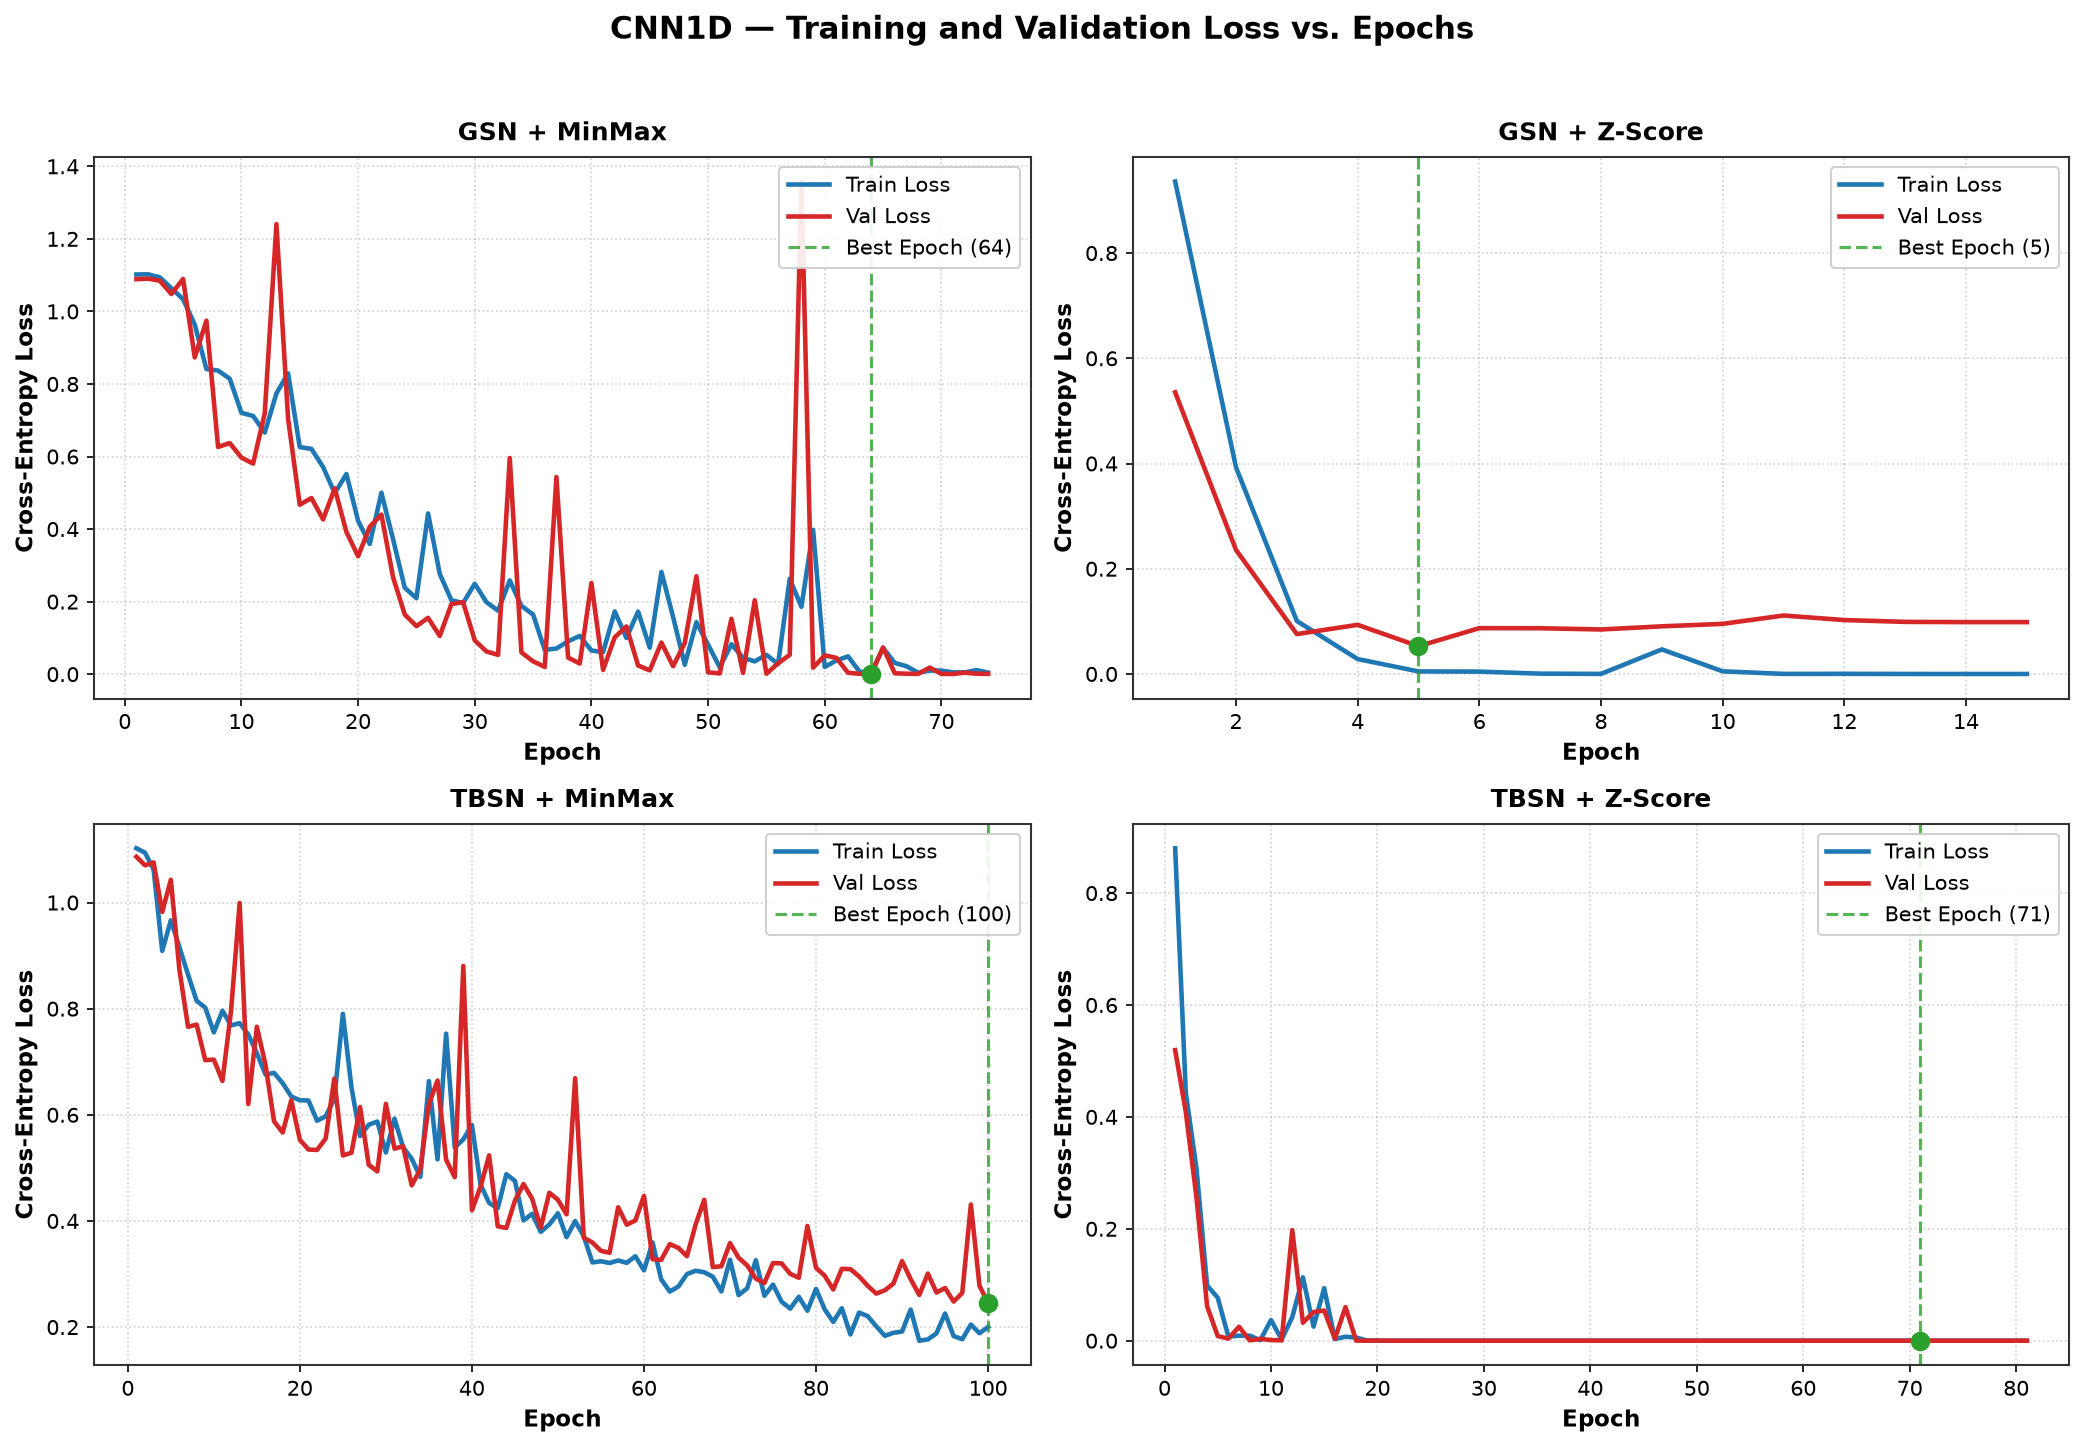

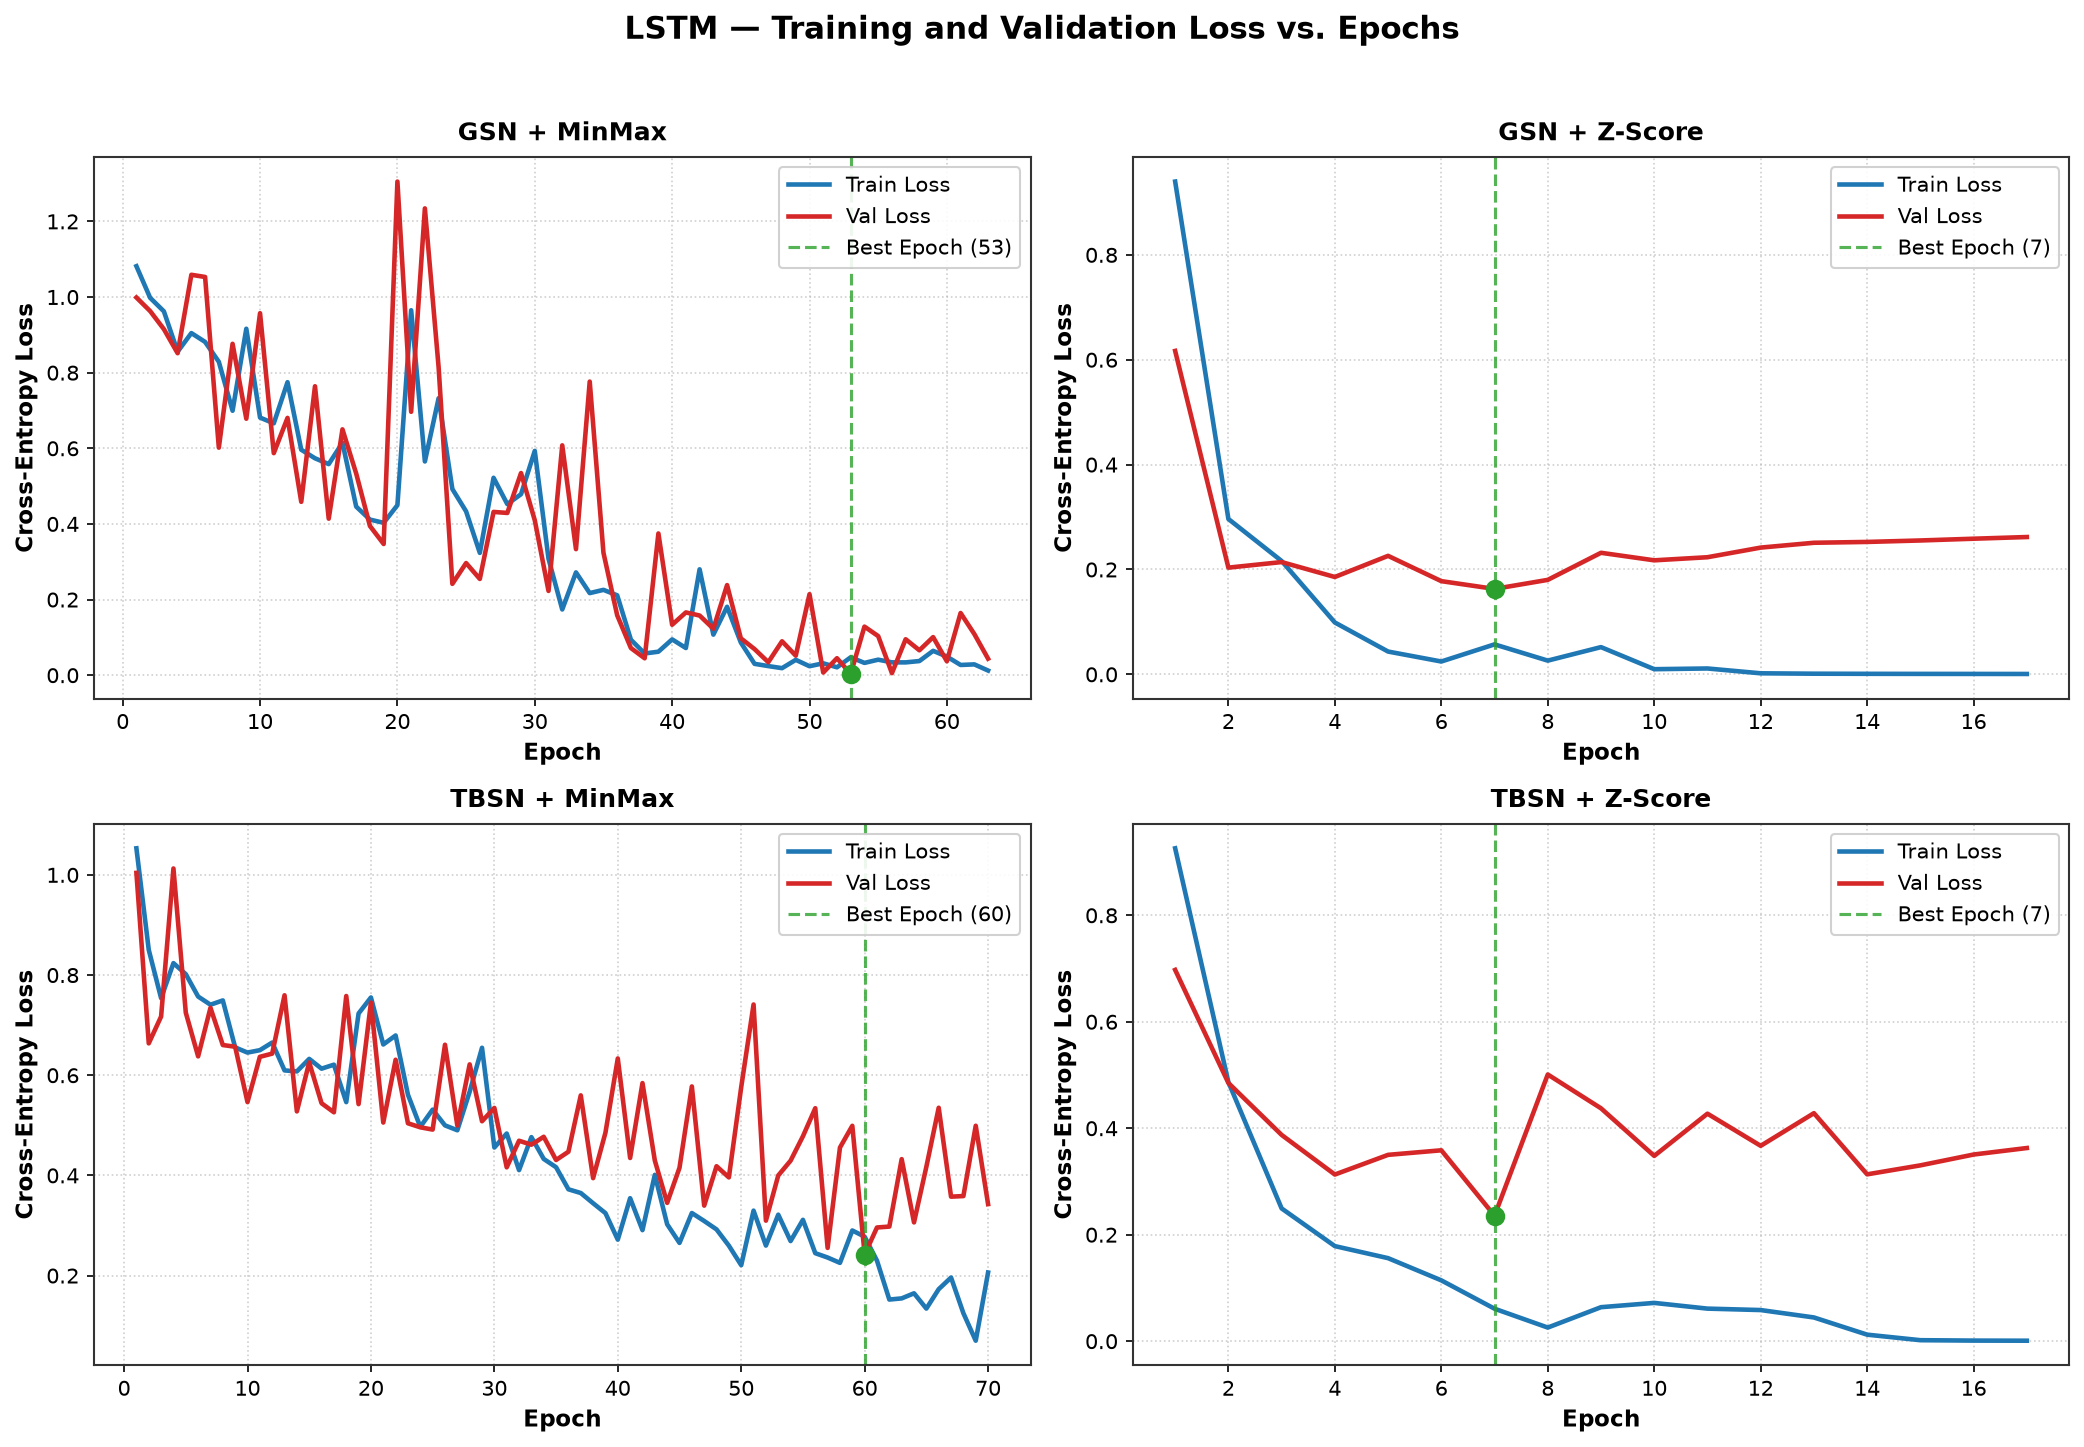

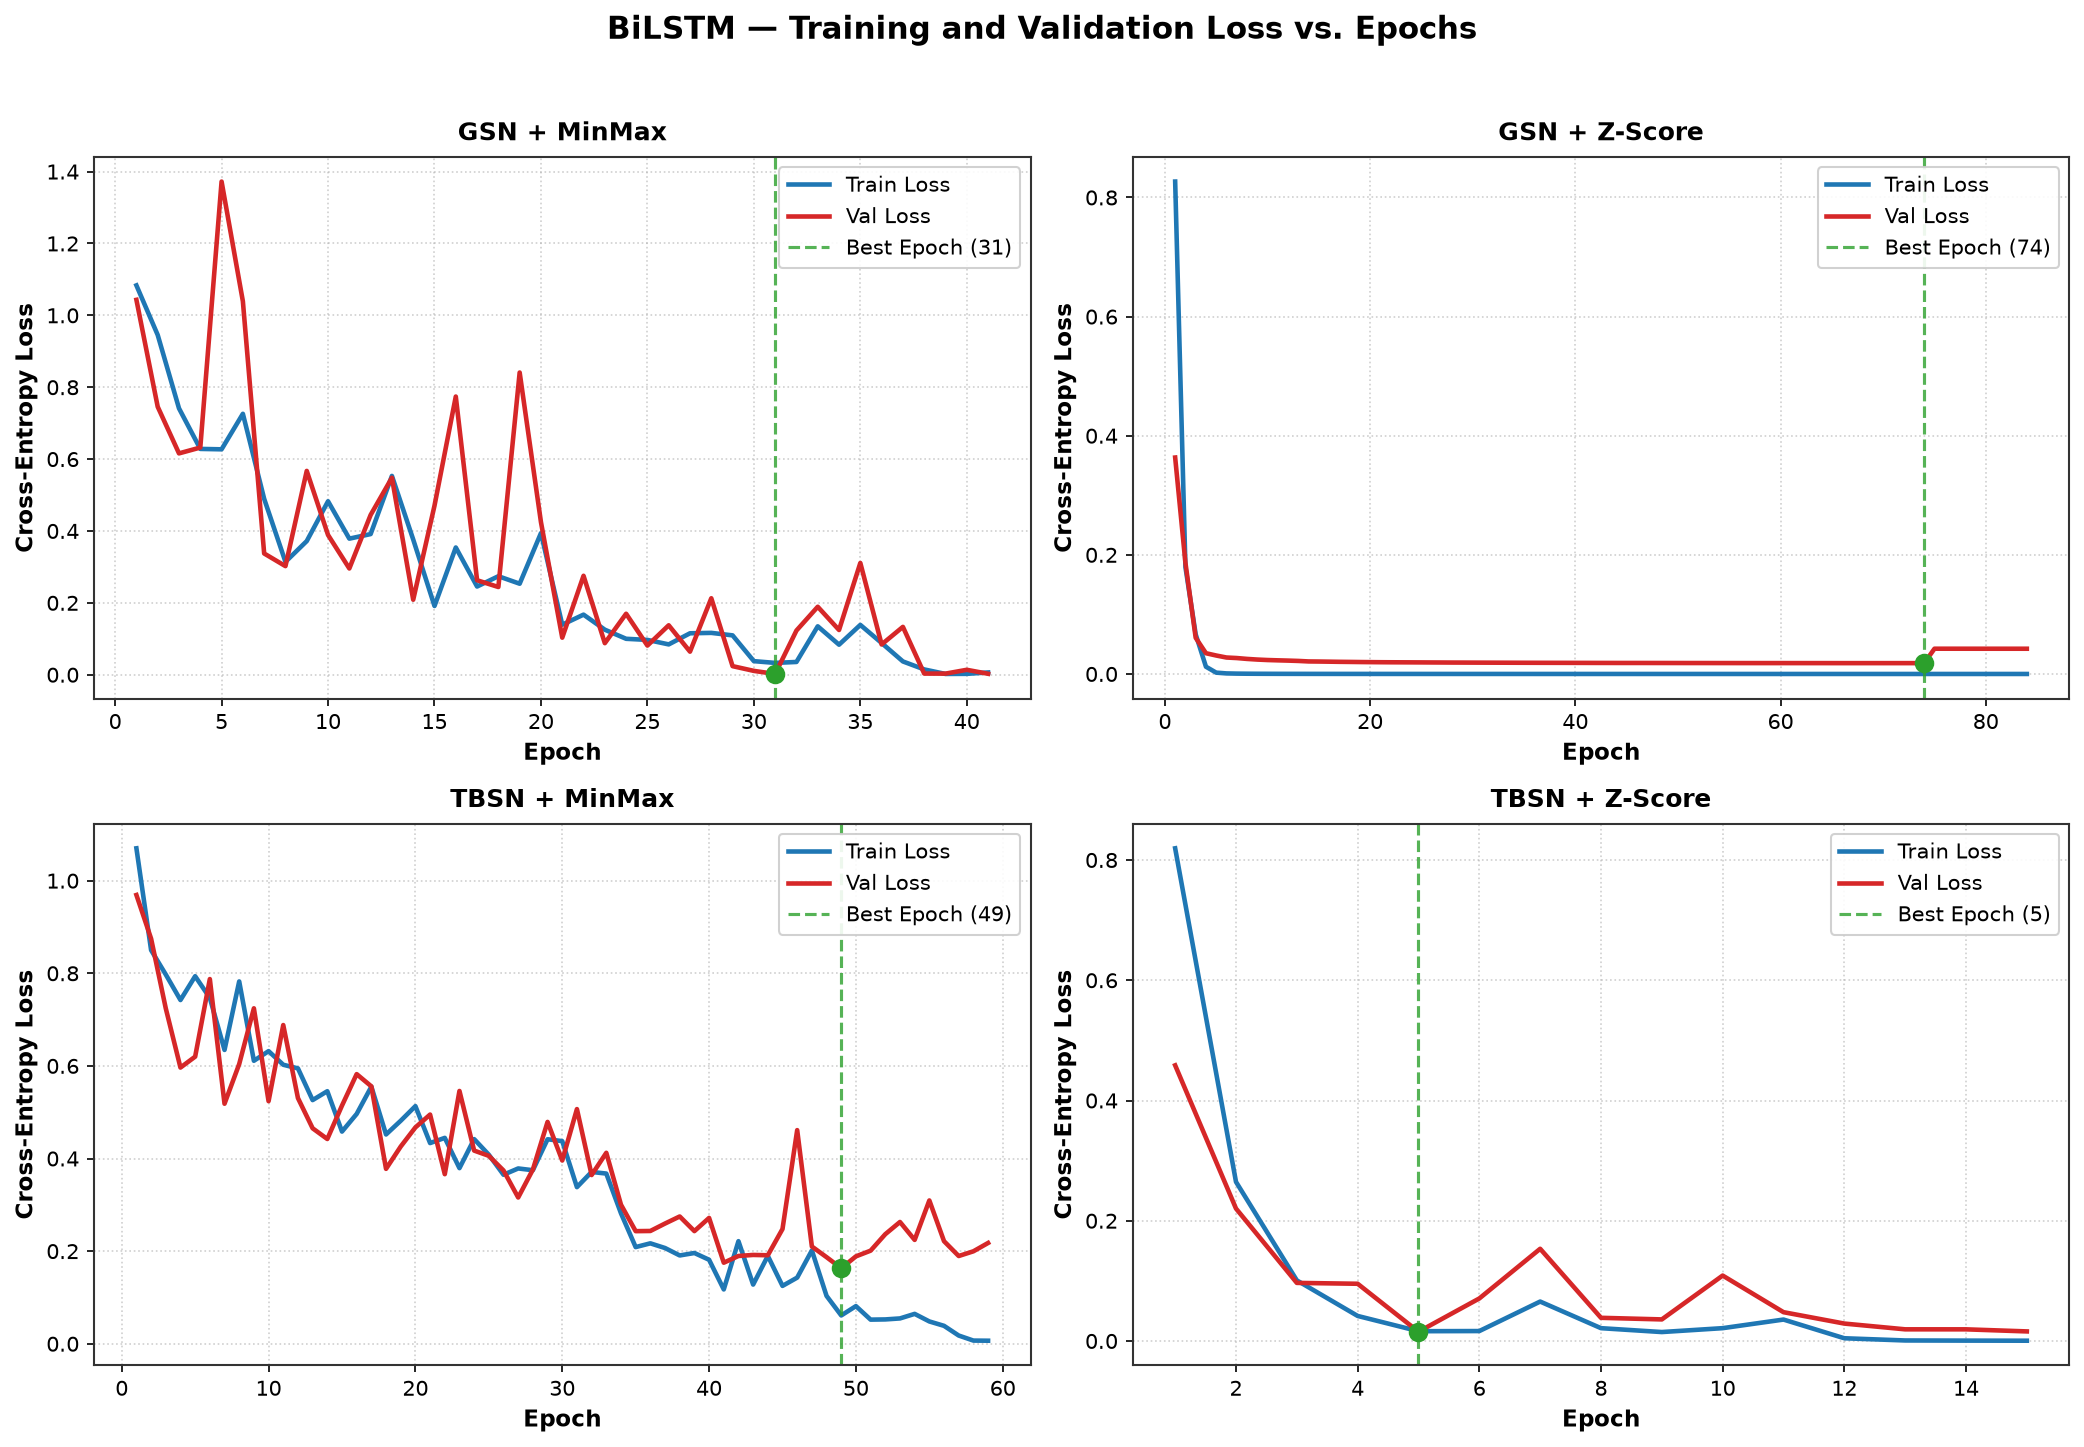

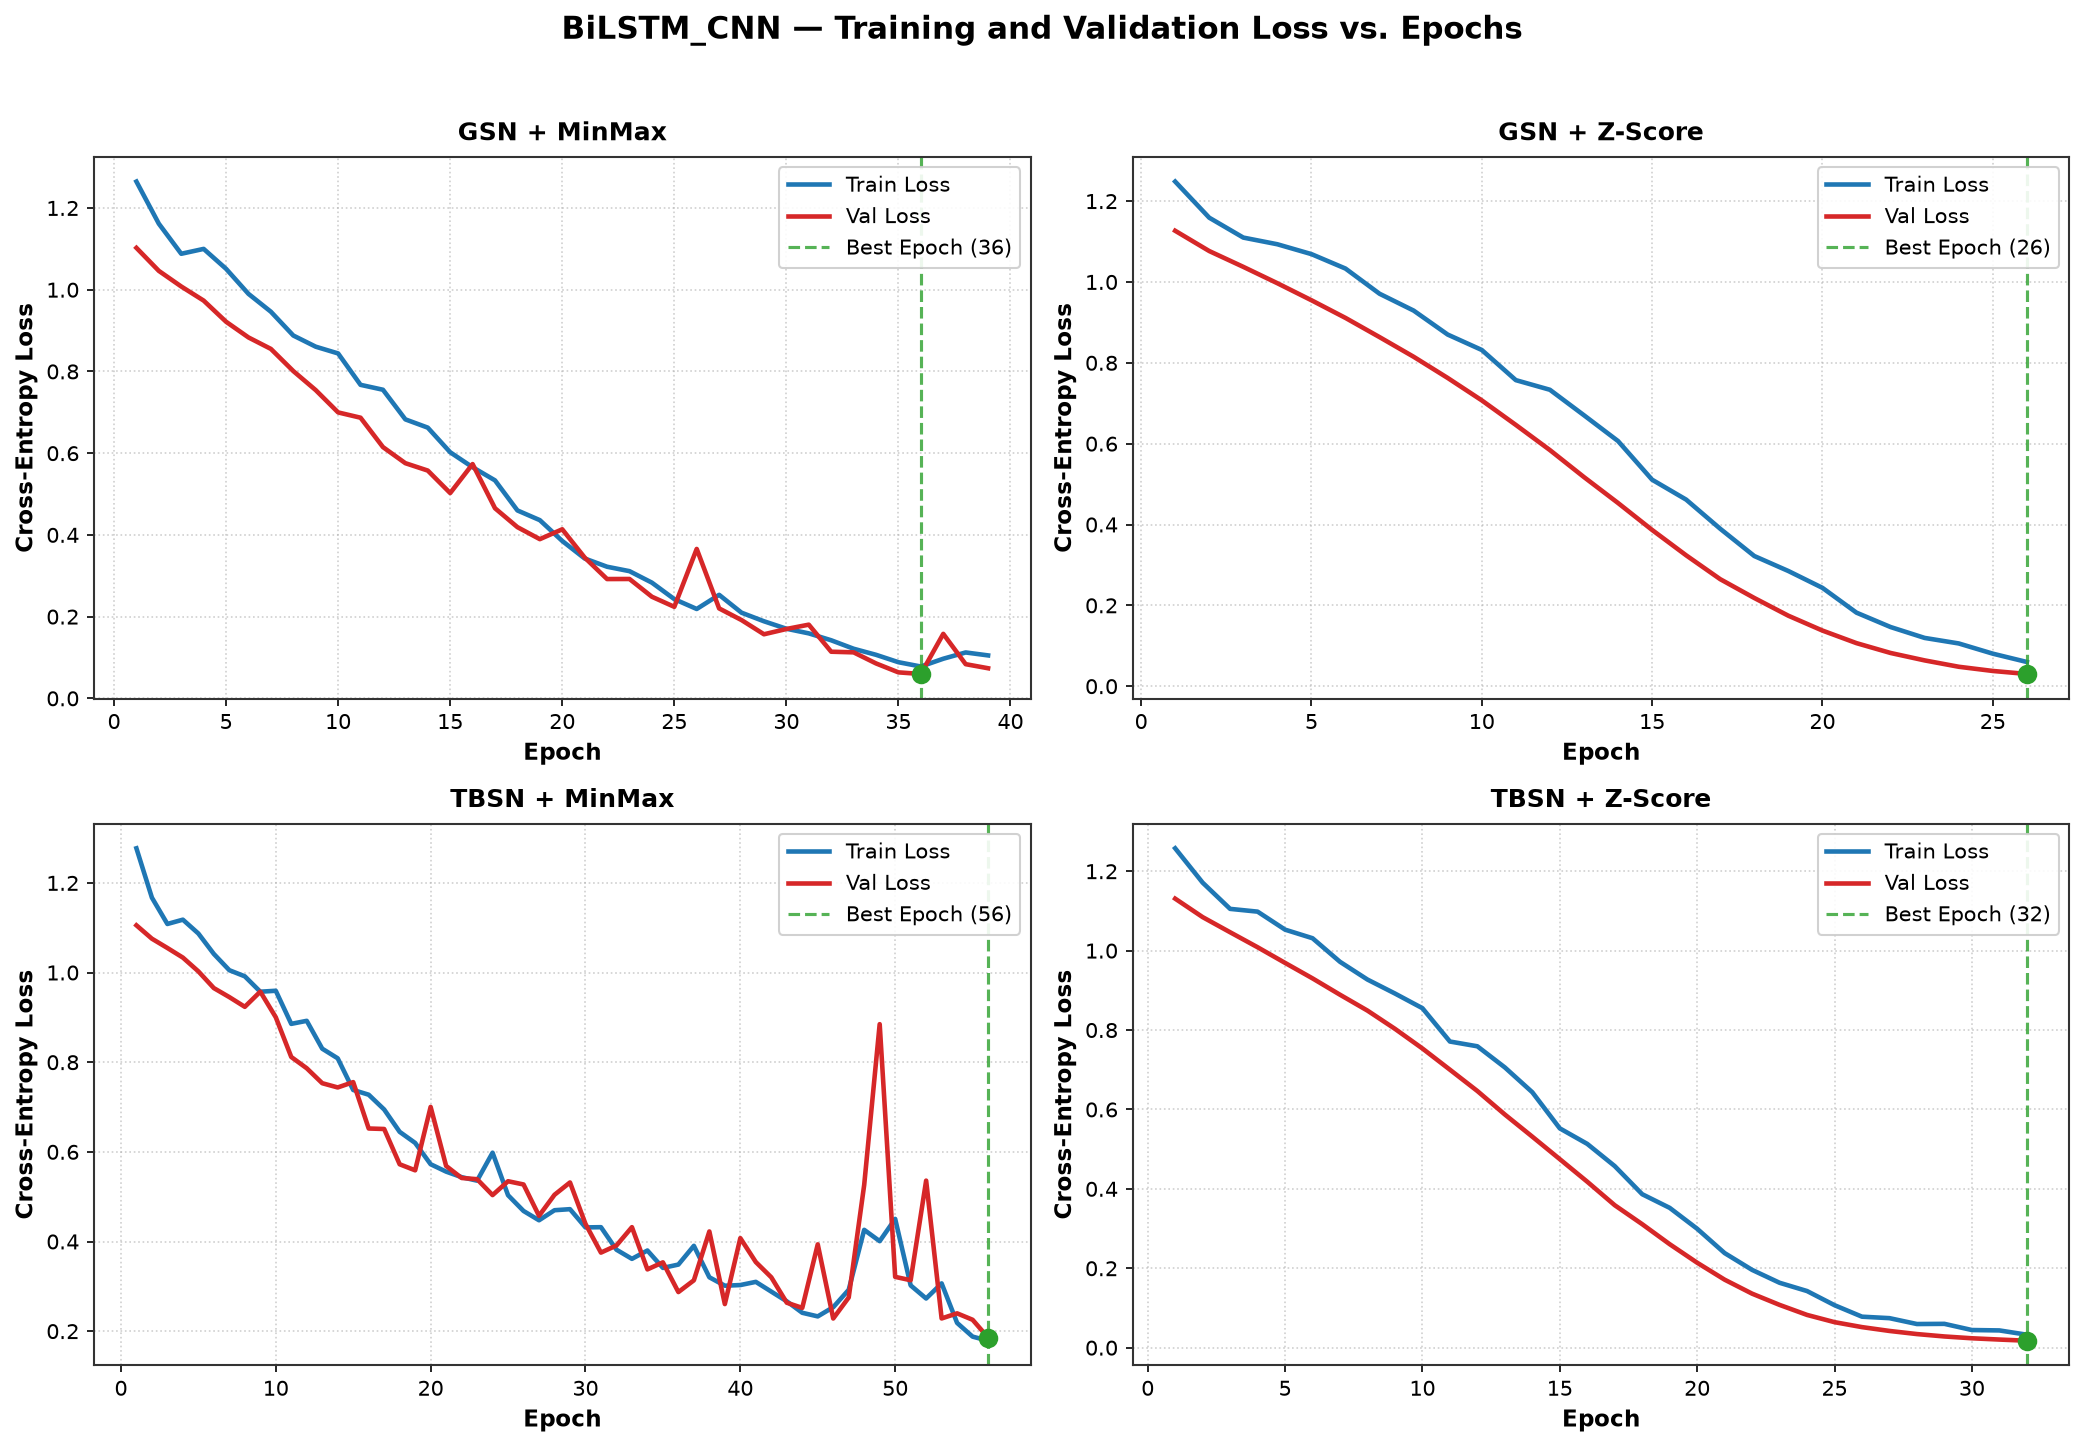

In [3]:
# ============================================================================
# CELL 3: FIGURE TYPE 1 — LOSS CURVES (4 DEEP MODELS x 4 BRANCHES)
# ============================================================================
loss_figures_generated = []

for model in DEEP_MODELS:
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=False, sharey=False)
    axes_flat = axes.flatten()
    
    for idx, branch in enumerate(BRANCHES):
        ax = axes_flat[idx]
        sub = df_history[(df_history['model'] == model) & (df_history['branch'] == branch)].sort_values('epoch')
        best_ep = int(df_metrics[(df_metrics['model'] == model) & (df_metrics['branch'] == branch)]['best_epoch'].values[0])
        
        # Plot curves
        ax.plot(sub['epoch'], sub['train_loss'], label='Train Loss', color='#1f77b4', lw=2.2)
        ax.plot(sub['epoch'], sub['val_loss'], label='Val Loss', color='#d62728', lw=2.2)
        
        # Highlight best epoch
        if best_ep in sub['epoch'].values:
            val_at_best = float(sub[sub['epoch'] == best_ep]['val_loss'].values[0])
            ax.axvline(best_ep, color='#2ca02c', linestyle='--', lw=1.5, alpha=0.8, label=f'Best Epoch ({best_ep})')
            ax.scatter([best_ep], [val_at_best], color='#2ca02c', s=70, zorder=5)
        
        ax.set_title(BRANCH_TITLES[branch], fontsize=12, fontweight='bold', pad=8)
        ax.set_xlabel('Epoch', fontsize=11, fontweight='bold')
        ax.set_ylabel('Cross-Entropy Loss', fontsize=11, fontweight='bold')
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.legend(fontsize=10, loc='upper right', framealpha=0.9)
        
    fig.suptitle(f"{model} — Training and Validation Loss vs. Epochs", fontsize=15, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0.02, 1, 0.96])
    
    png_path = FIGURES_DIR / f"{model}_training_validation_loss.png"
    pdf_path = FIGURES_DIR / f"{model}_training_validation_loss.pdf"
    plt.savefig(png_path, dpi=300, bbox_inches='tight')
    plt.savefig(pdf_path, bbox_inches='tight')
    plt.show() # Display inline in notebook
    plt.close(fig)
    
    loss_figures_generated.append((model, png_path, pdf_path))
    print(f"Generated Loss Figure: {png_path.name} | {pdf_path.name}")

print(f"\n[SUCCESS] Completed {len(loss_figures_generated)} Loss curve figures (PNG and PDF).")

---
## 4. Figure Type 2 — Training and Validation Accuracy vs. Epochs

Generate one publication-quality figure for each of the four epoch-trained models (`CNN1D`, `LSTM`, `BiLSTM`, `BiLSTM_CNN`).
Each figure contains a 2×2 grid displaying the four preprocessing branches with actual recorded `train_accuracy` and `val_accuracy` plotted on a consistent 0–1 scale.

Generated Accuracy Figure: CNN1D_training_validation_accuracy.png | CNN1D_training_validation_accuracy.pdf
Generated Accuracy Figure: LSTM_training_validation_accuracy.png | LSTM_training_validation_accuracy.pdf
Generated Accuracy Figure: BiLSTM_training_validation_accuracy.png | BiLSTM_training_validation_accuracy.pdf
Generated Accuracy Figure: BiLSTM_CNN_training_validation_accuracy.png | BiLSTM_CNN_training_validation_accuracy.pdf

[SUCCESS] Completed 4 Accuracy curve figures (PNG and PDF).


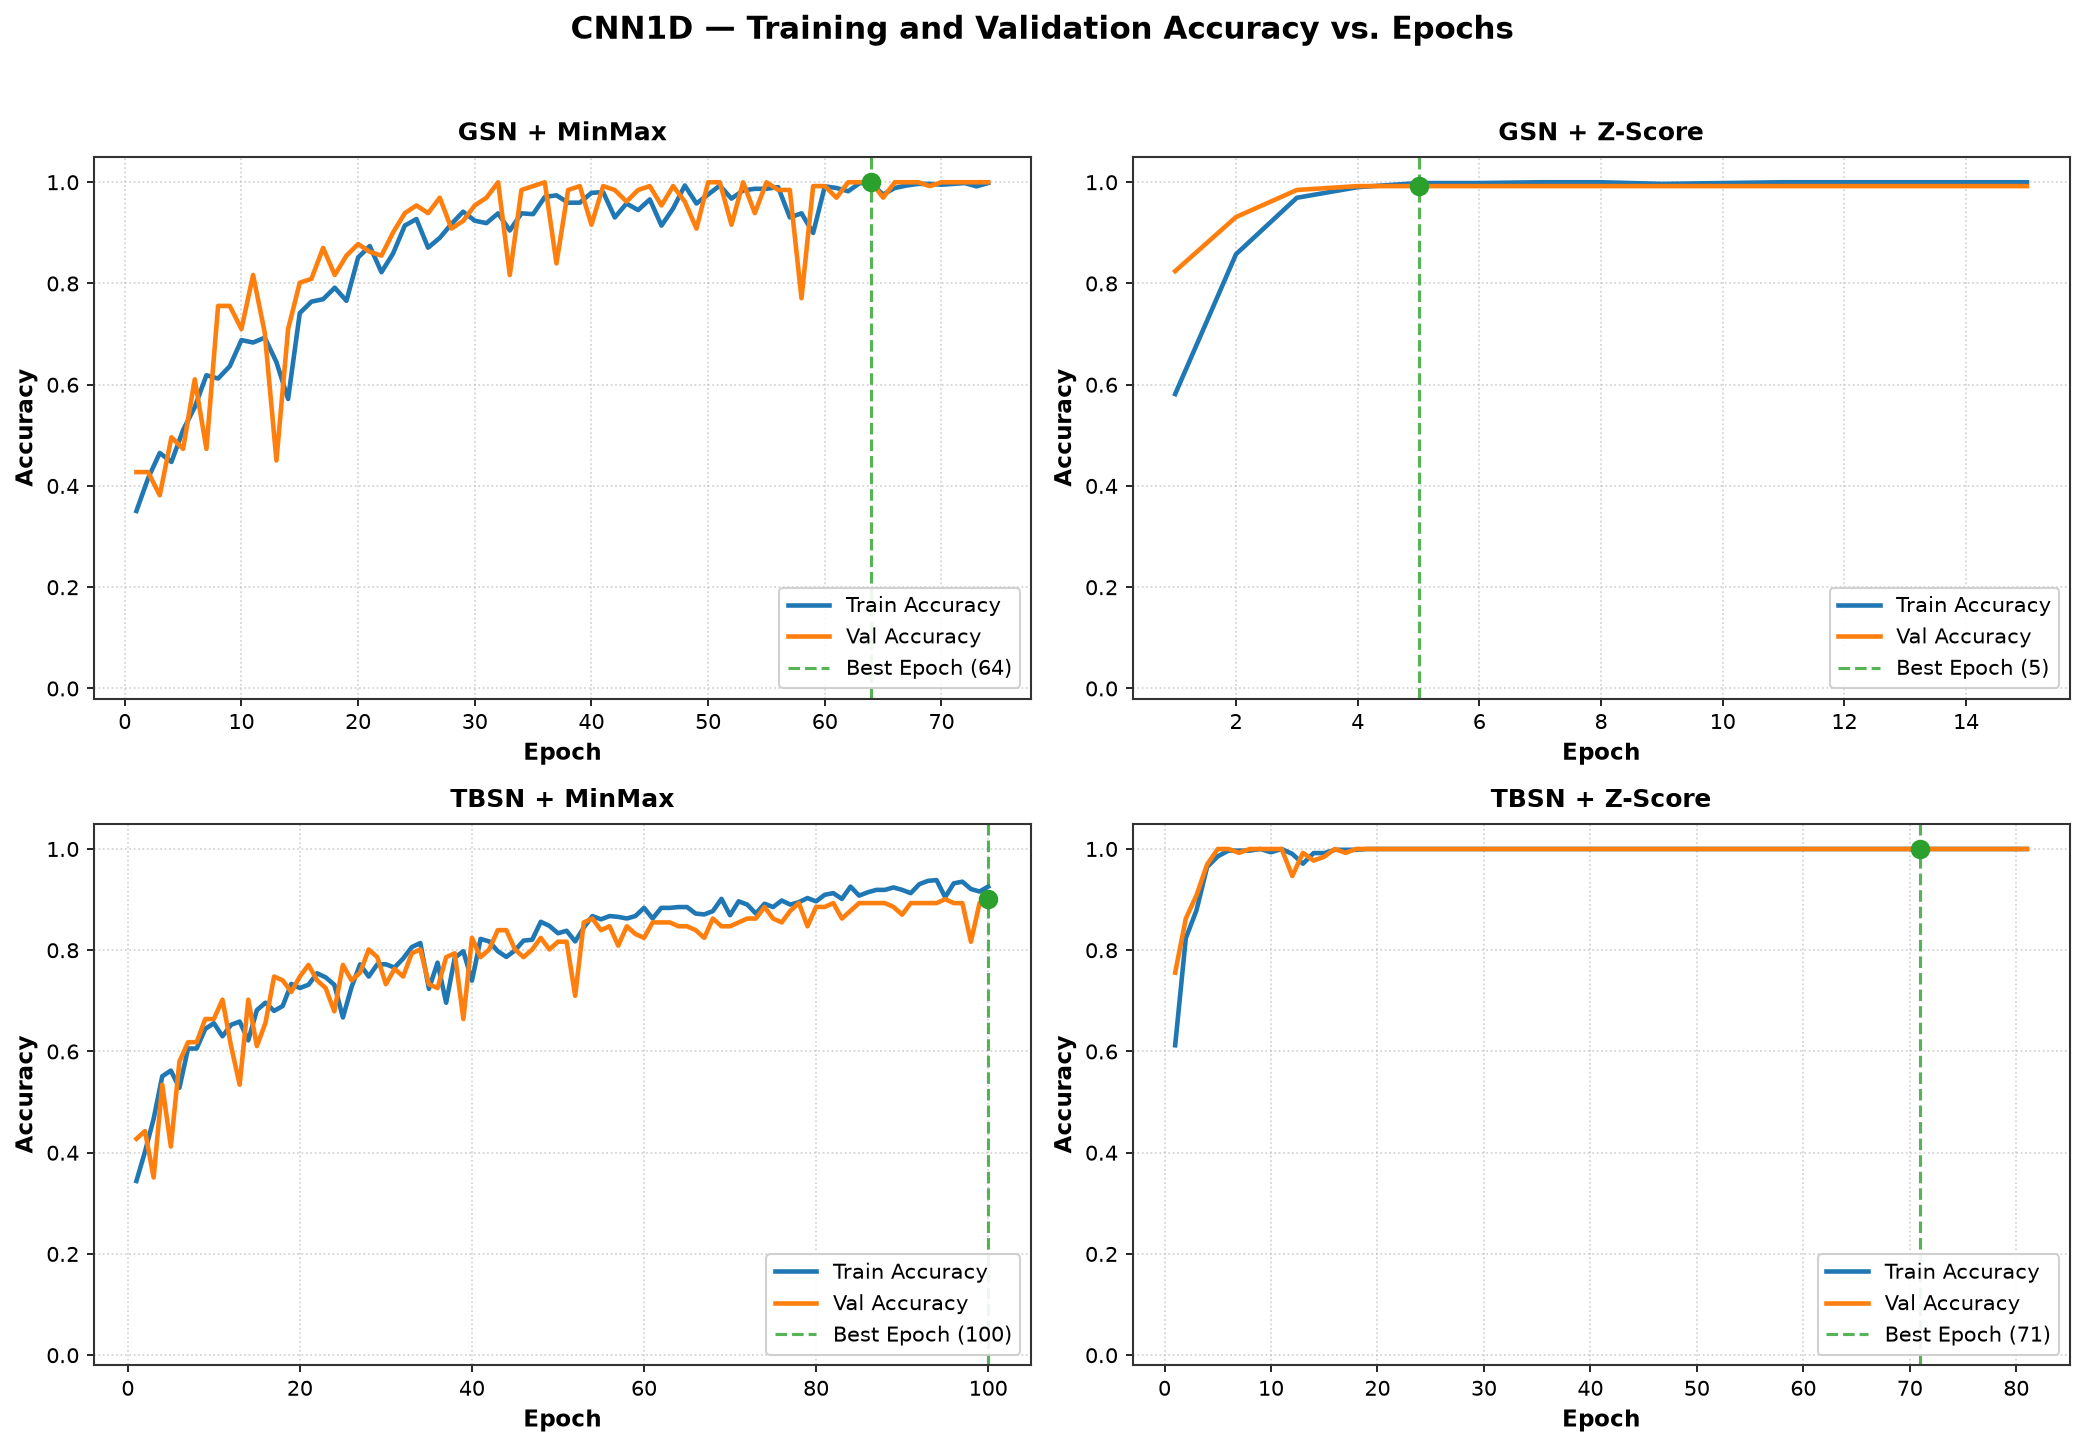

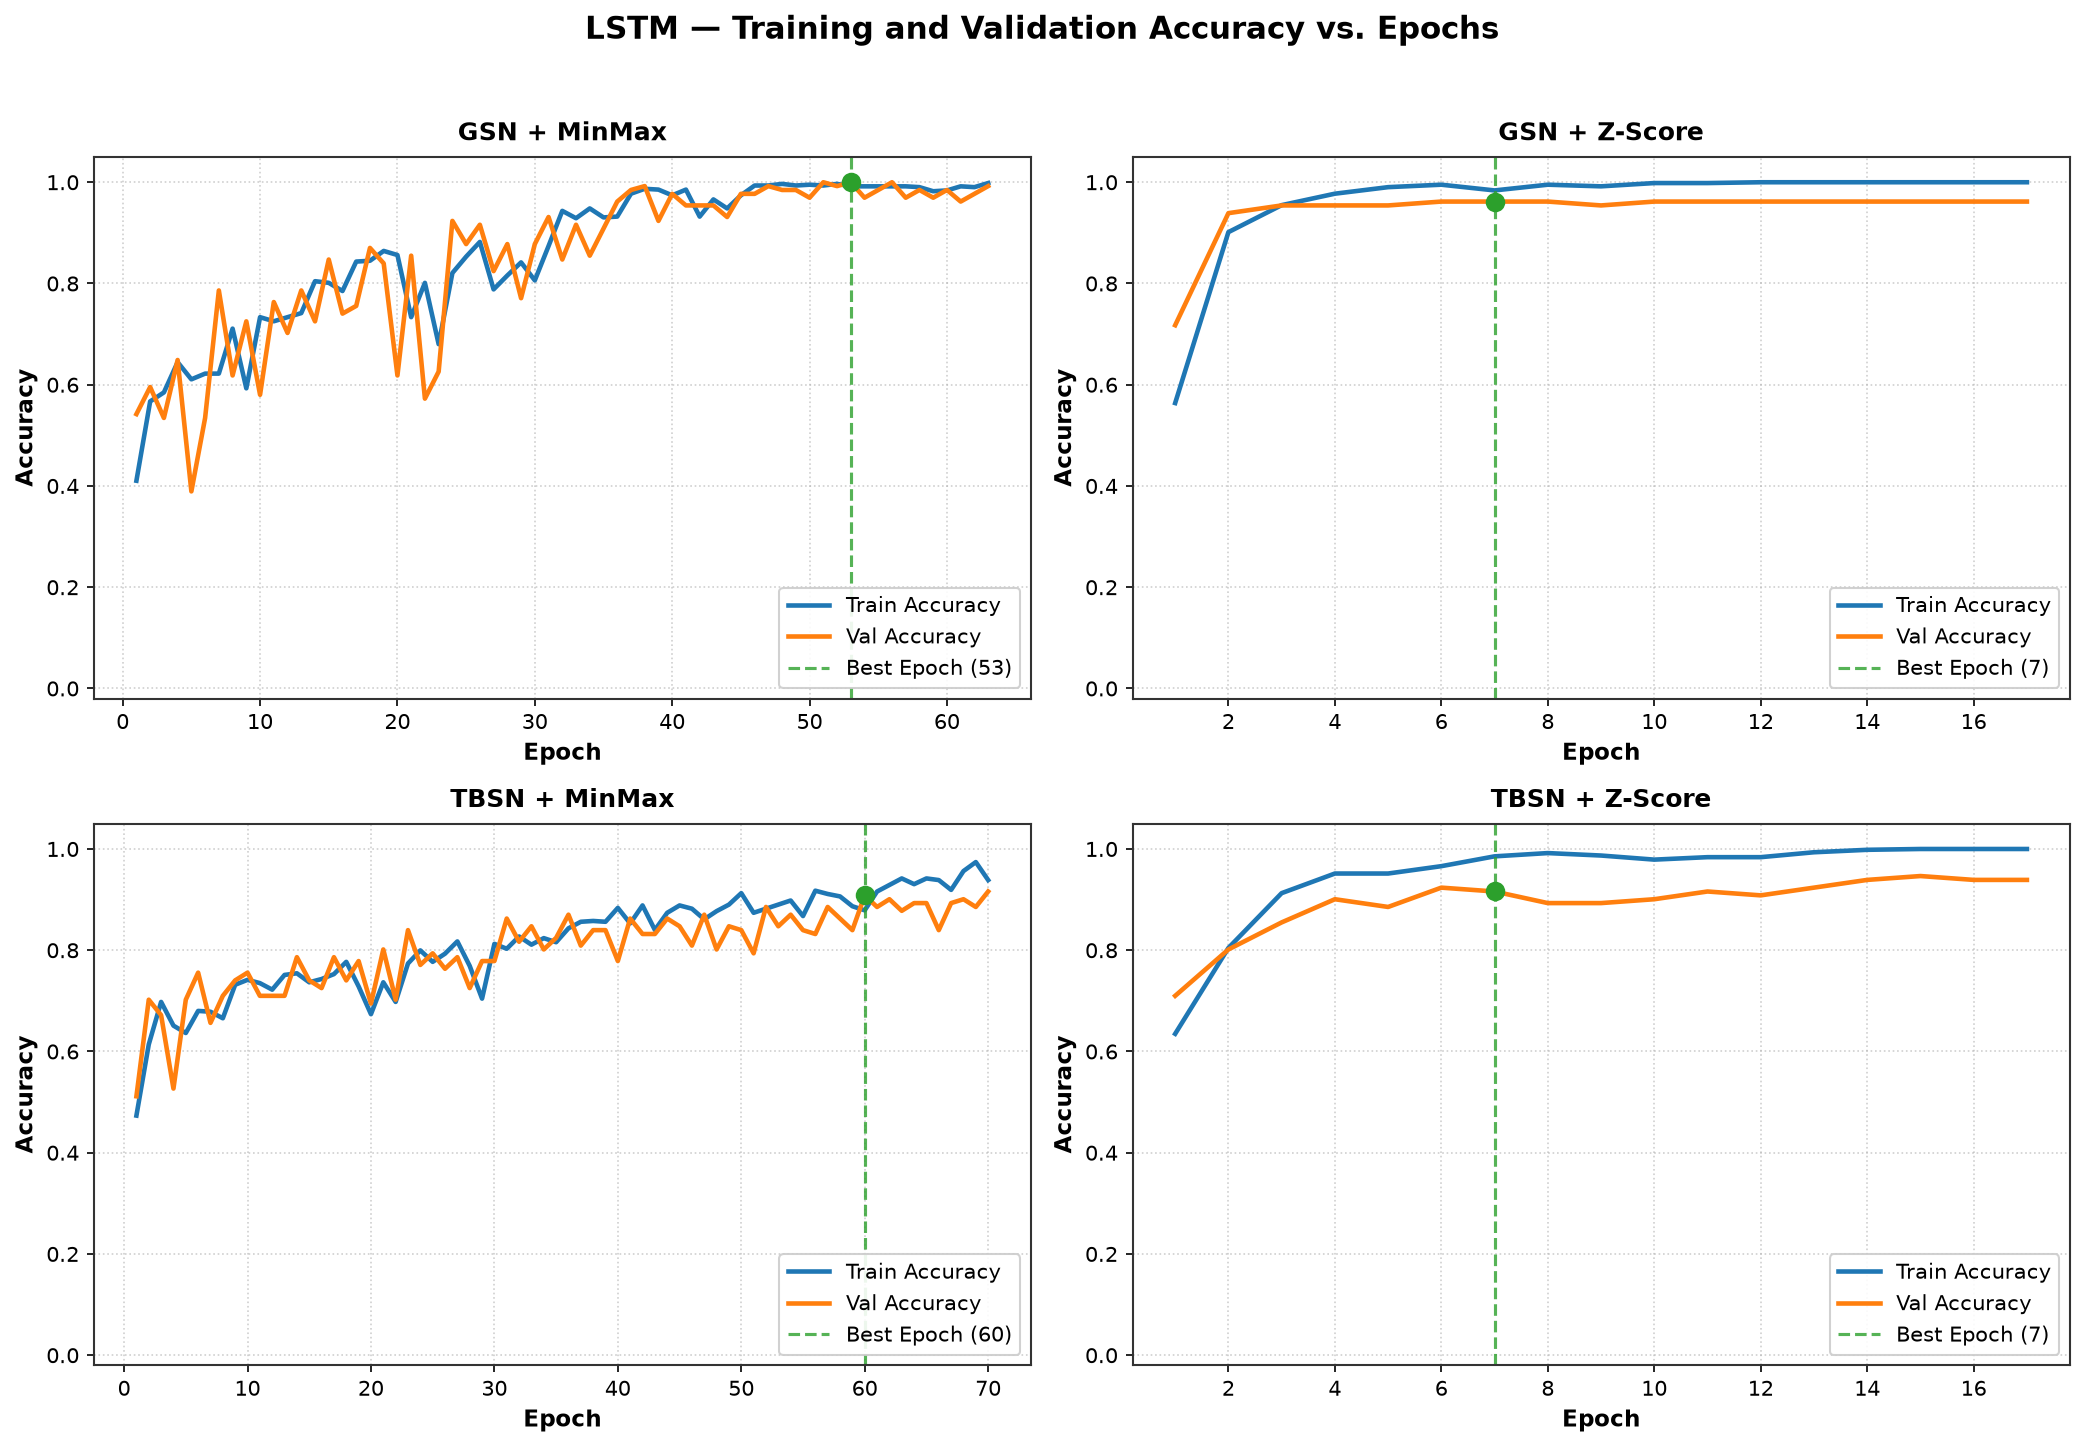

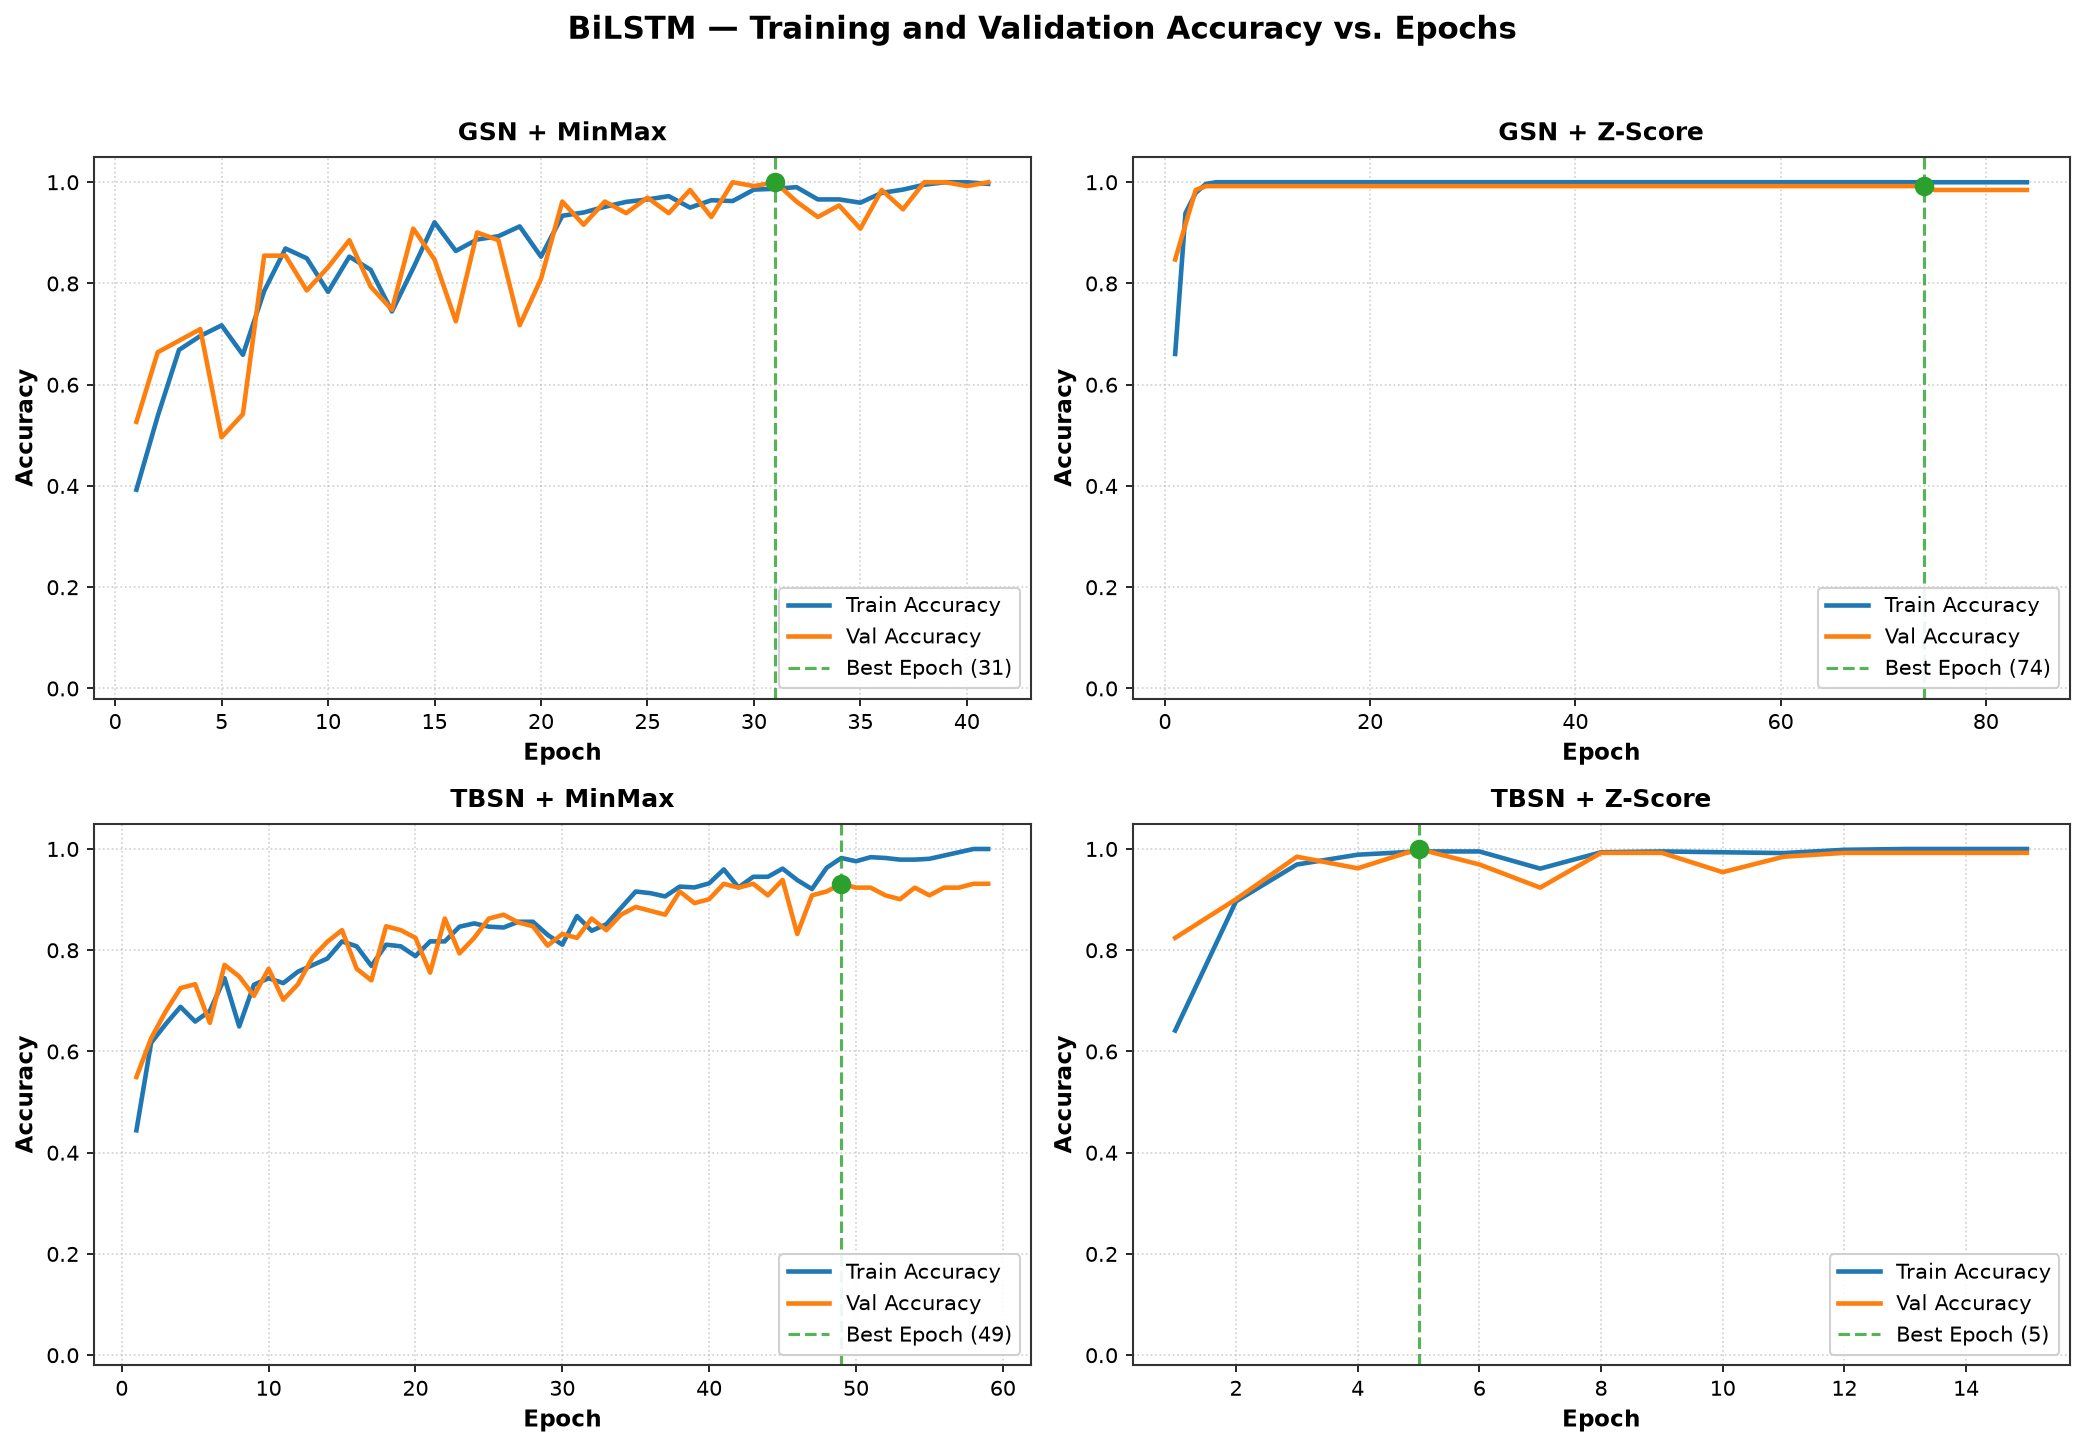

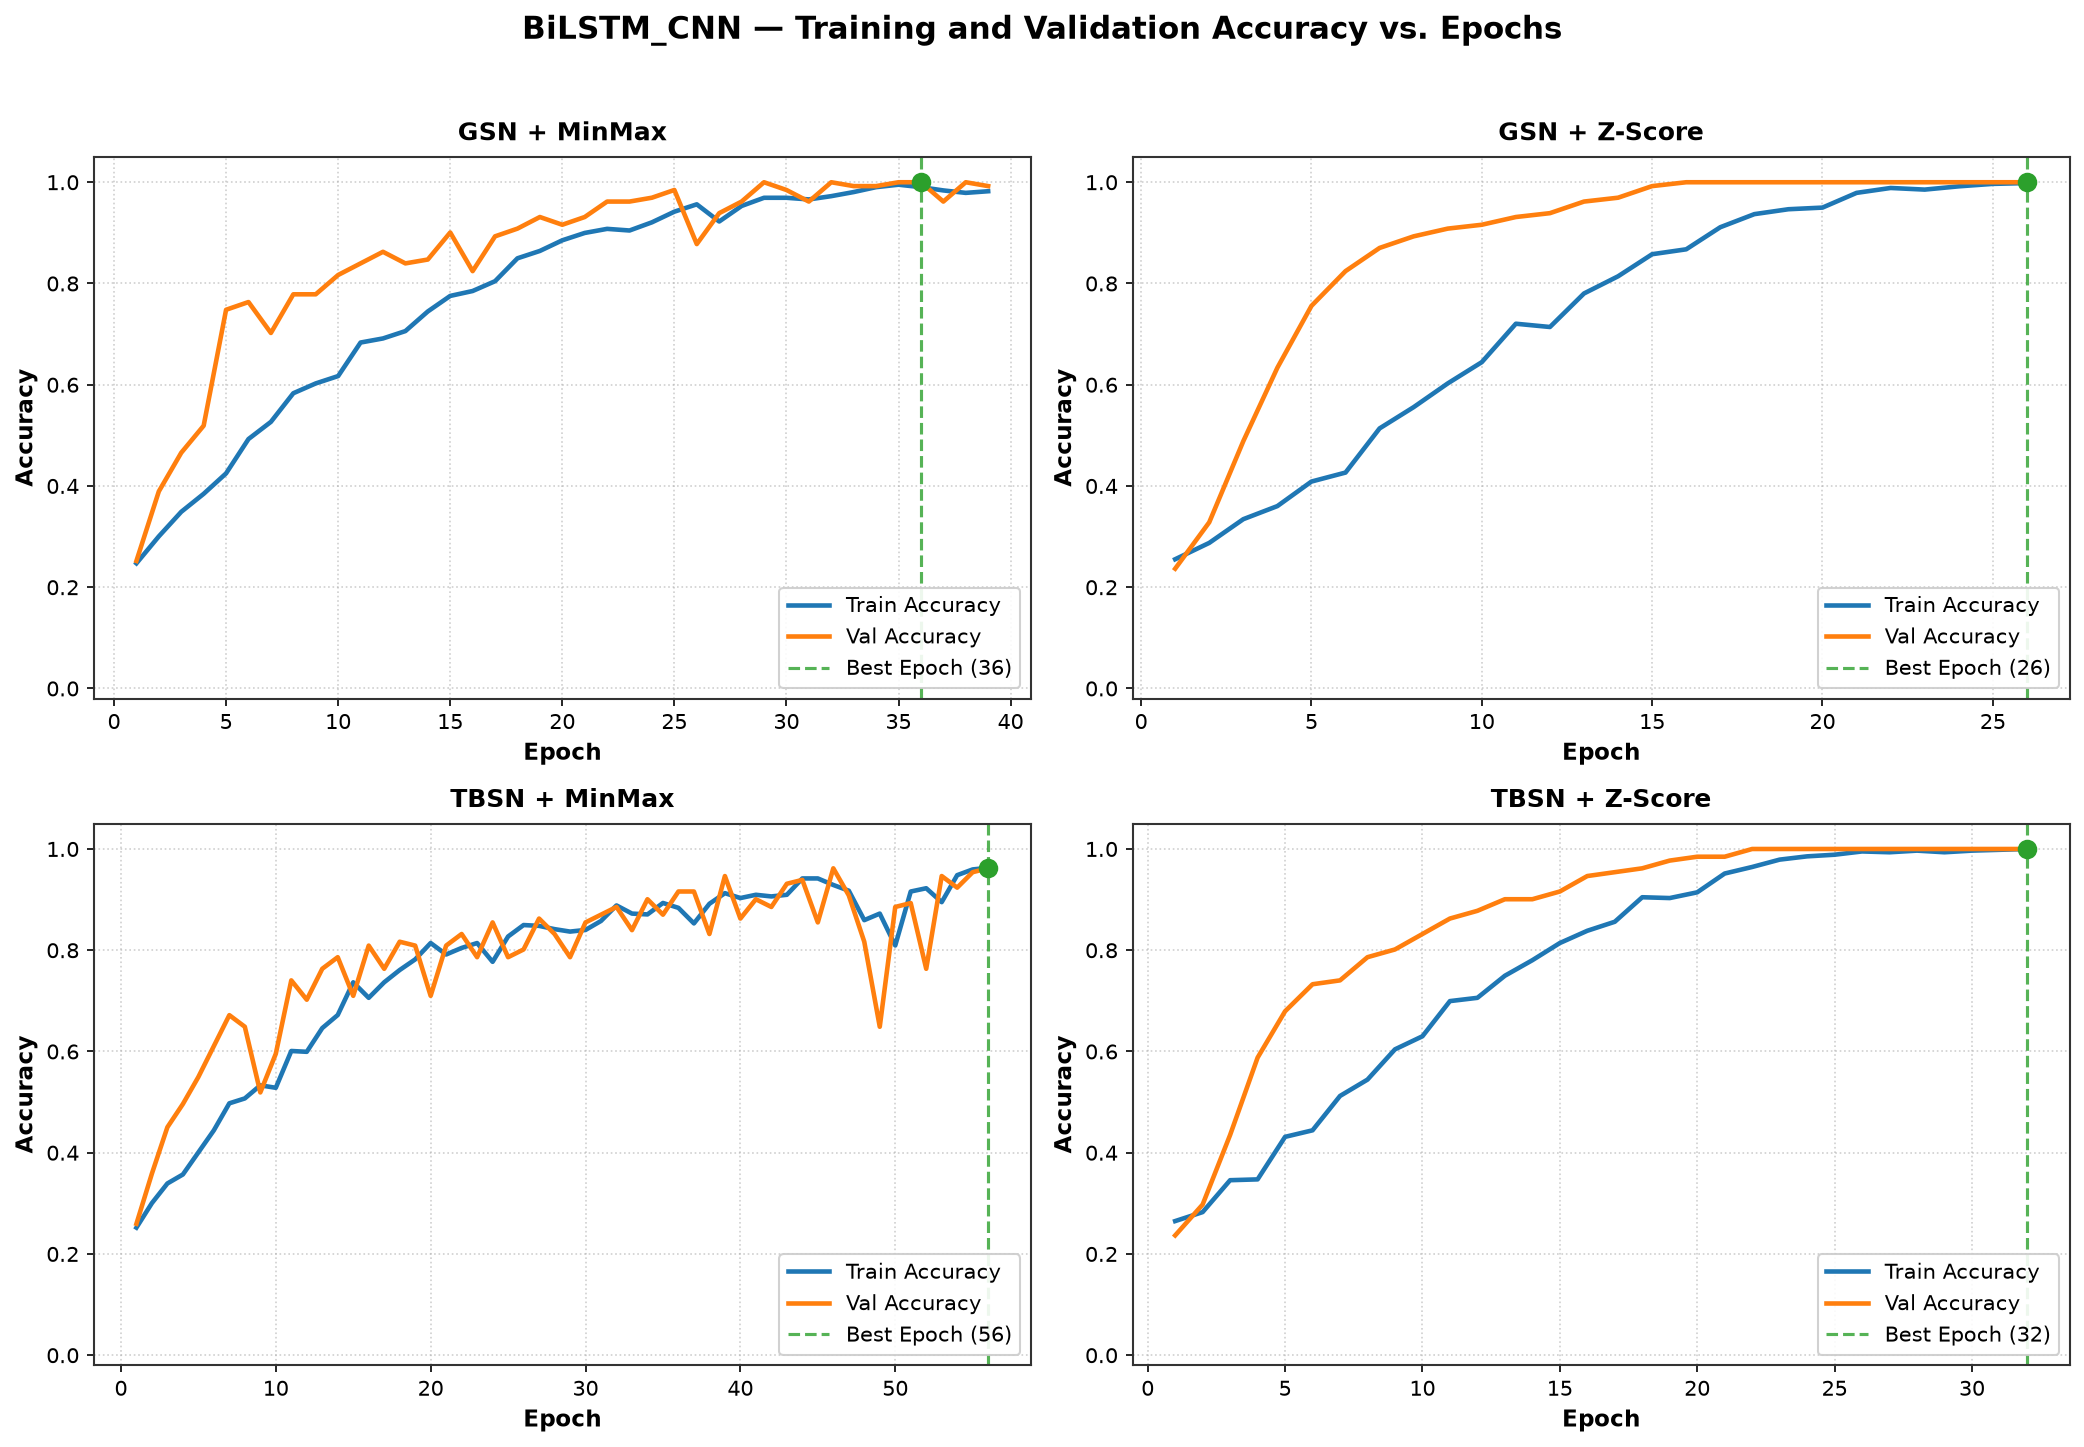

In [4]:
# ============================================================================
# CELL 4: FIGURE TYPE 2 — ACCURACY CURVES (4 DEEP MODELS x 4 BRANCHES)
# ============================================================================
acc_figures_generated = []

for model in DEEP_MODELS:
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=False, sharey=False)
    axes_flat = axes.flatten()
    
    for idx, branch in enumerate(BRANCHES):
        ax = axes_flat[idx]
        sub = df_history[(df_history['model'] == model) & (df_history['branch'] == branch)].sort_values('epoch')
        best_ep = int(df_metrics[(df_metrics['model'] == model) & (df_metrics['branch'] == branch)]['best_epoch'].values[0])
        
        # Plot curves
        ax.plot(sub['epoch'], sub['train_accuracy'], label='Train Accuracy', color='#1f77b4', lw=2.2)
        ax.plot(sub['epoch'], sub['val_accuracy'], label='Val Accuracy', color='#ff7f0e', lw=2.2)
        
        # Highlight best epoch
        if best_ep in sub['epoch'].values:
            acc_at_best = float(sub[sub['epoch'] == best_ep]['val_accuracy'].values[0])
            ax.axvline(best_ep, color='#2ca02c', linestyle='--', lw=1.5, alpha=0.8, label=f'Best Epoch ({best_ep})')
            ax.scatter([best_ep], [acc_at_best], color='#2ca02c', s=70, zorder=5)
        
        ax.set_title(BRANCH_TITLES[branch], fontsize=12, fontweight='bold', pad=8)
        ax.set_xlabel('Epoch', fontsize=11, fontweight='bold')
        ax.set_ylabel('Accuracy', fontsize=11, fontweight='bold')
        ax.set_ylim(-0.02, 1.05) # Consistent 0-1 scale
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.legend(fontsize=10, loc='lower right', framealpha=0.9)
        
    fig.suptitle(f"{model} — Training and Validation Accuracy vs. Epochs", fontsize=15, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0.02, 1, 0.96])
    
    png_path = FIGURES_DIR / f"{model}_training_validation_accuracy.png"
    pdf_path = FIGURES_DIR / f"{model}_training_validation_accuracy.pdf"
    plt.savefig(png_path, dpi=300, bbox_inches='tight')
    plt.savefig(pdf_path, bbox_inches='tight')
    plt.show() # Display inline in notebook
    plt.close(fig)
    
    acc_figures_generated.append((model, png_path, pdf_path))
    print(f"Generated Accuracy Figure: {png_path.name} | {pdf_path.name}")

print(f"\n[SUCCESS] Completed {len(acc_figures_generated)} Accuracy curve figures (PNG and PDF).")

---
## 5. Figure Type 3 — Held-Out Test Confusion Matrices

Generate one publication-quality figure for each of the five models (including `Classical_LR`).
Each figure contains a 2×2 grid corresponding to the four preprocessing branches, displaying cell counts and row-normalized percentages on the held-out `trial_split` test set.

Generated Confusion Matrix Figure: CNN1D_confusion_matrices.png | CNN1D_confusion_matrices.pdf
Generated Confusion Matrix Figure: LSTM_confusion_matrices.png | LSTM_confusion_matrices.pdf
Generated Confusion Matrix Figure: BiLSTM_confusion_matrices.png | BiLSTM_confusion_matrices.pdf
Generated Confusion Matrix Figure: BiLSTM_CNN_confusion_matrices.png | BiLSTM_CNN_confusion_matrices.pdf
Generated Confusion Matrix Figure: Classical_LR_confusion_matrices.png | Classical_LR_confusion_matrices.pdf

[SUCCESS] Completed 5 Confusion matrix figures (PNG and PDF).


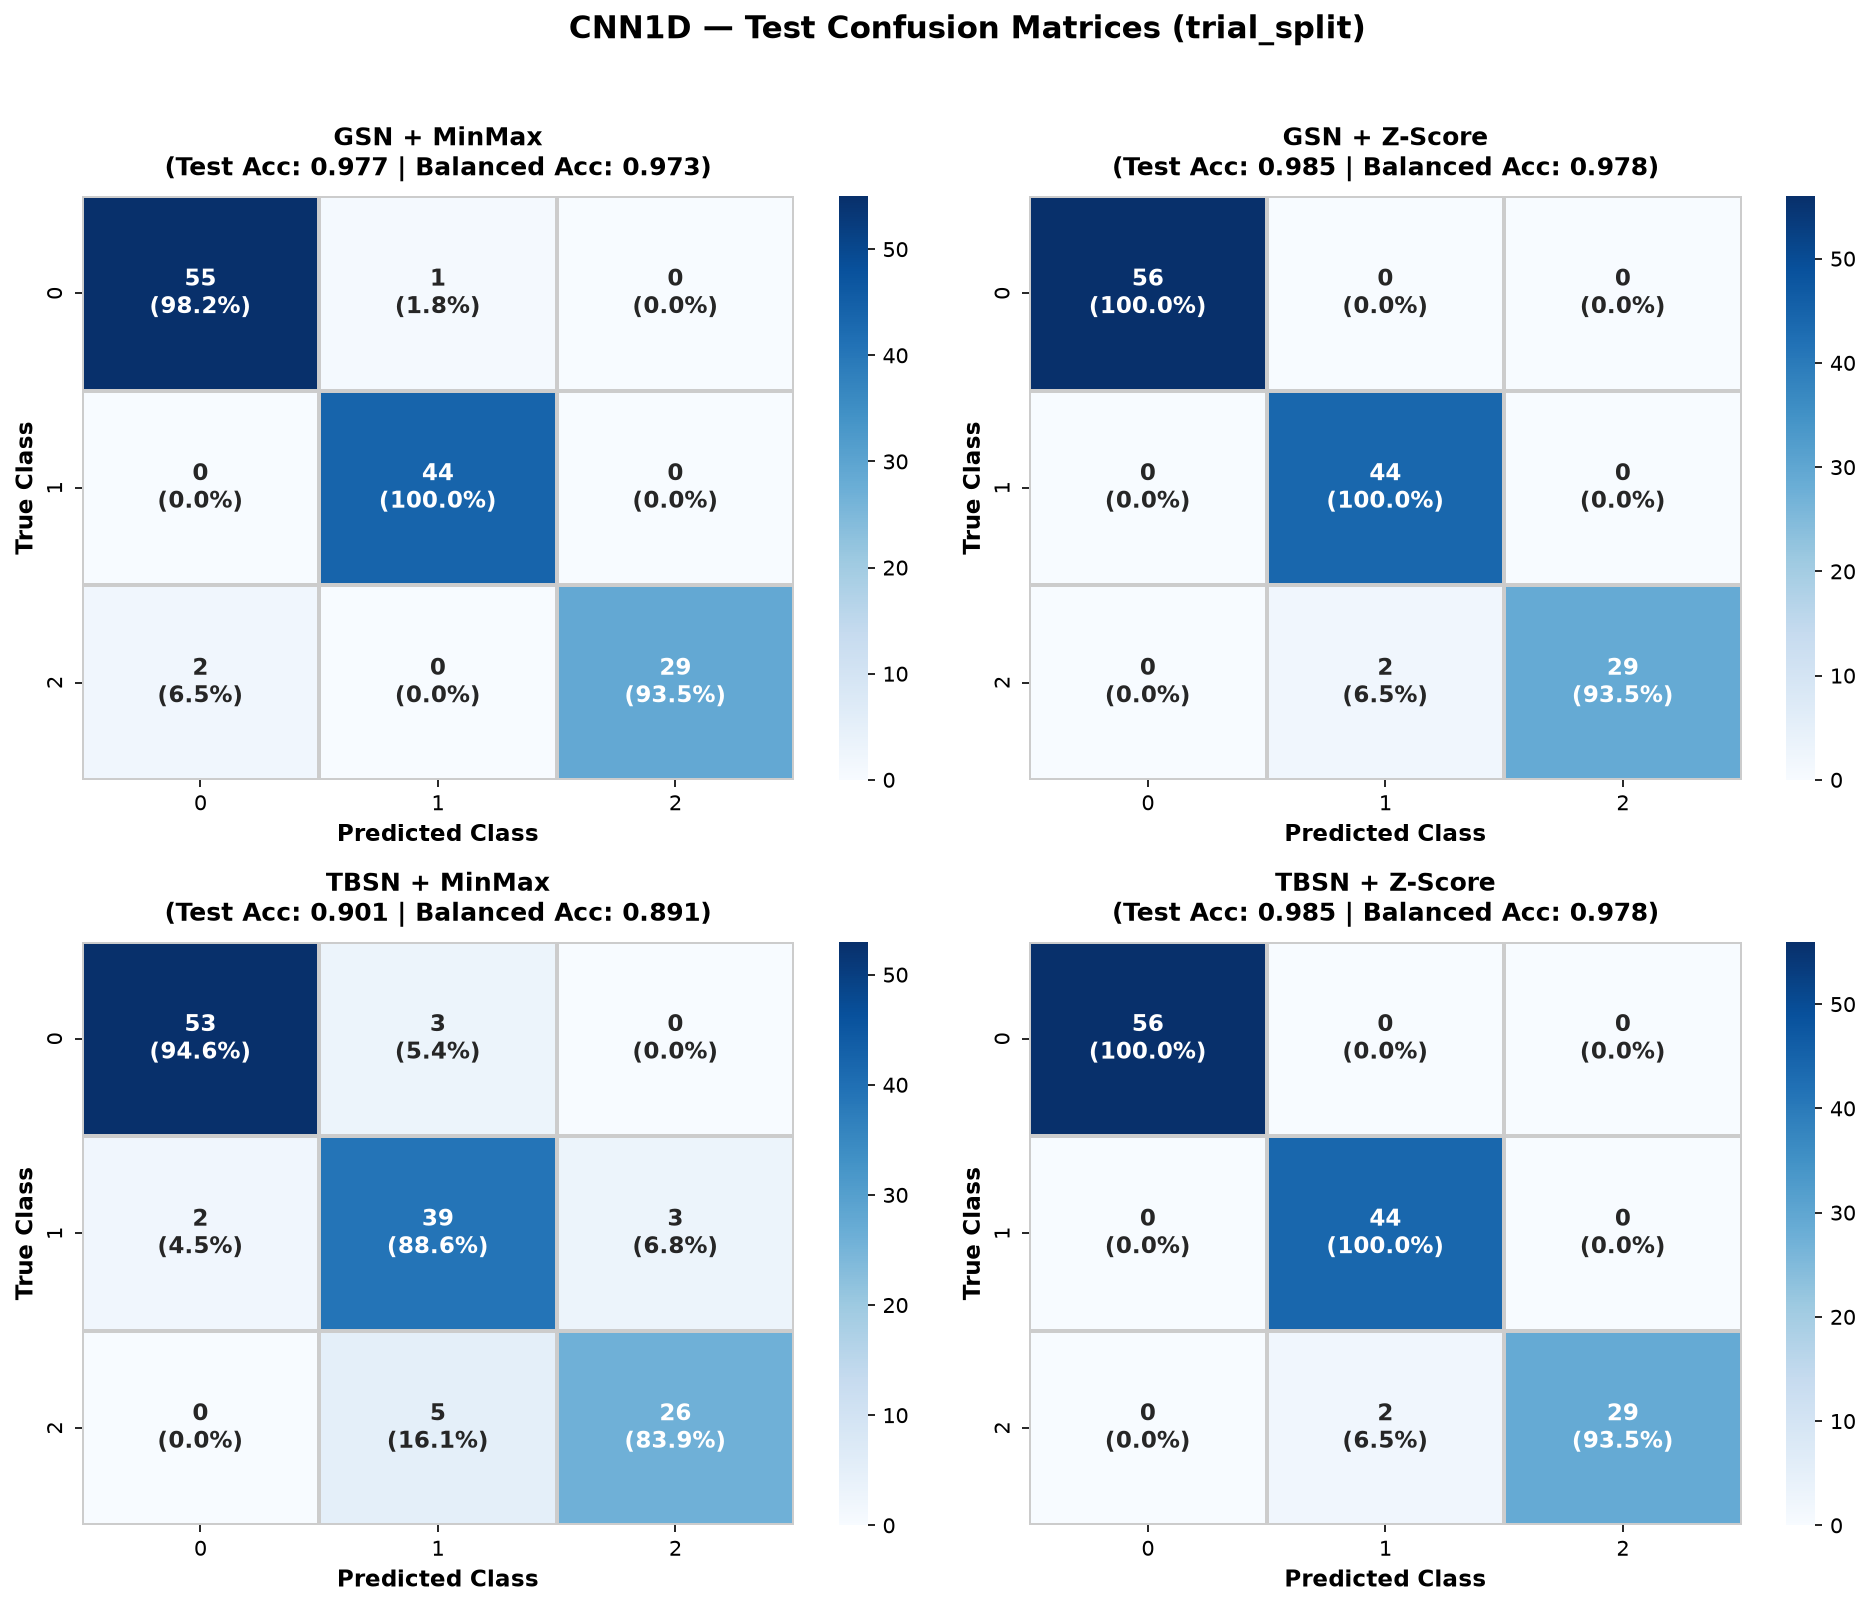

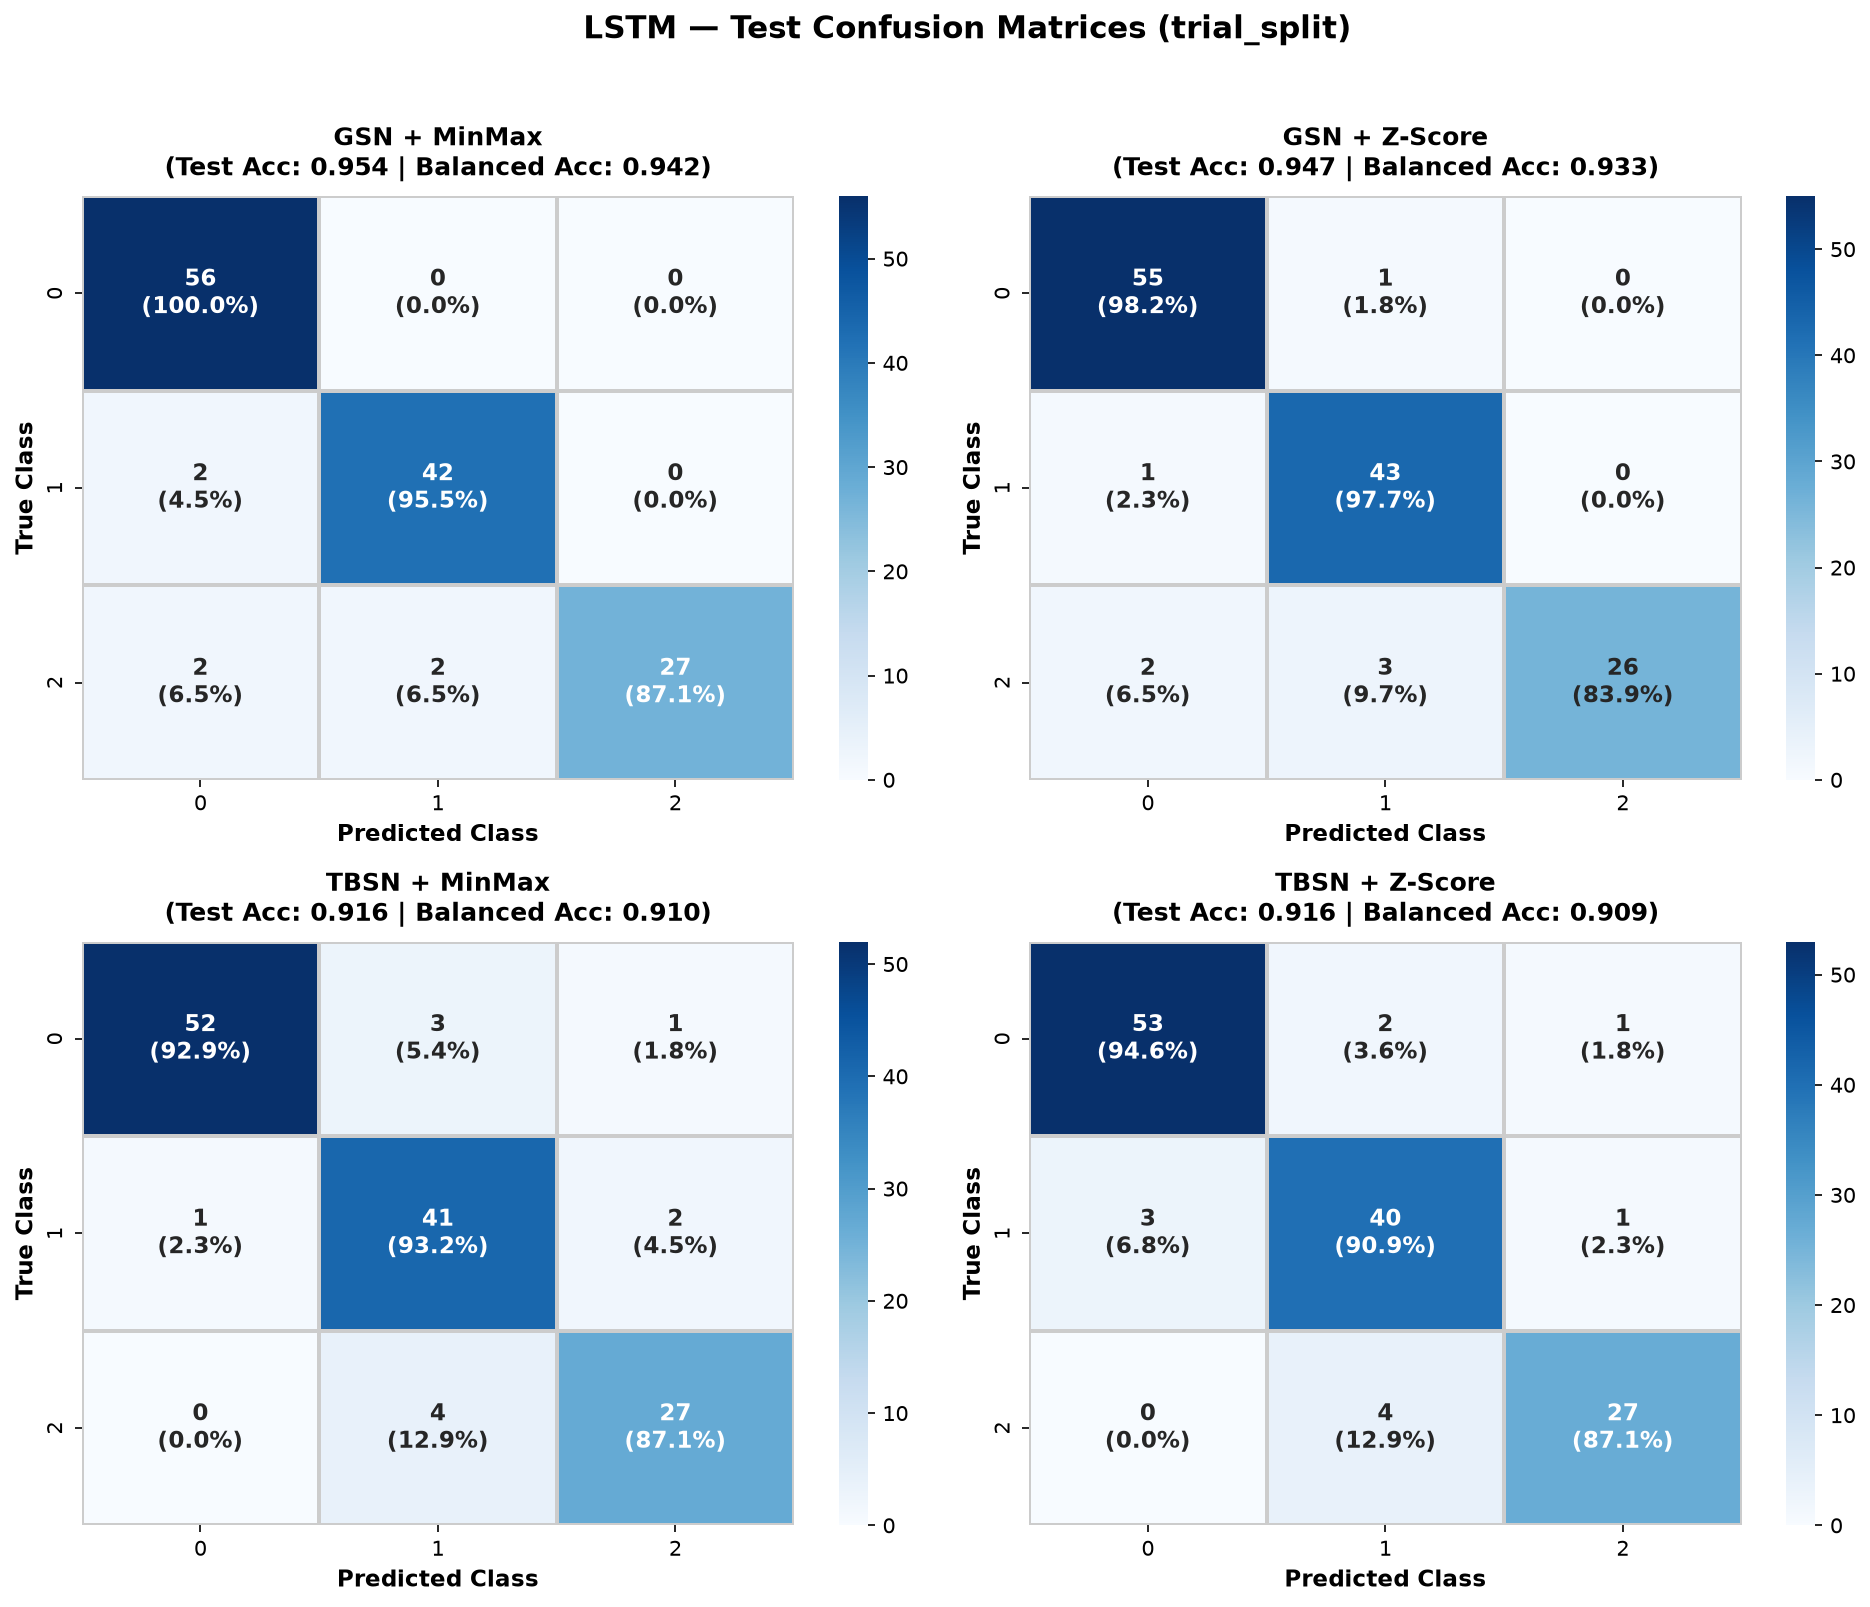

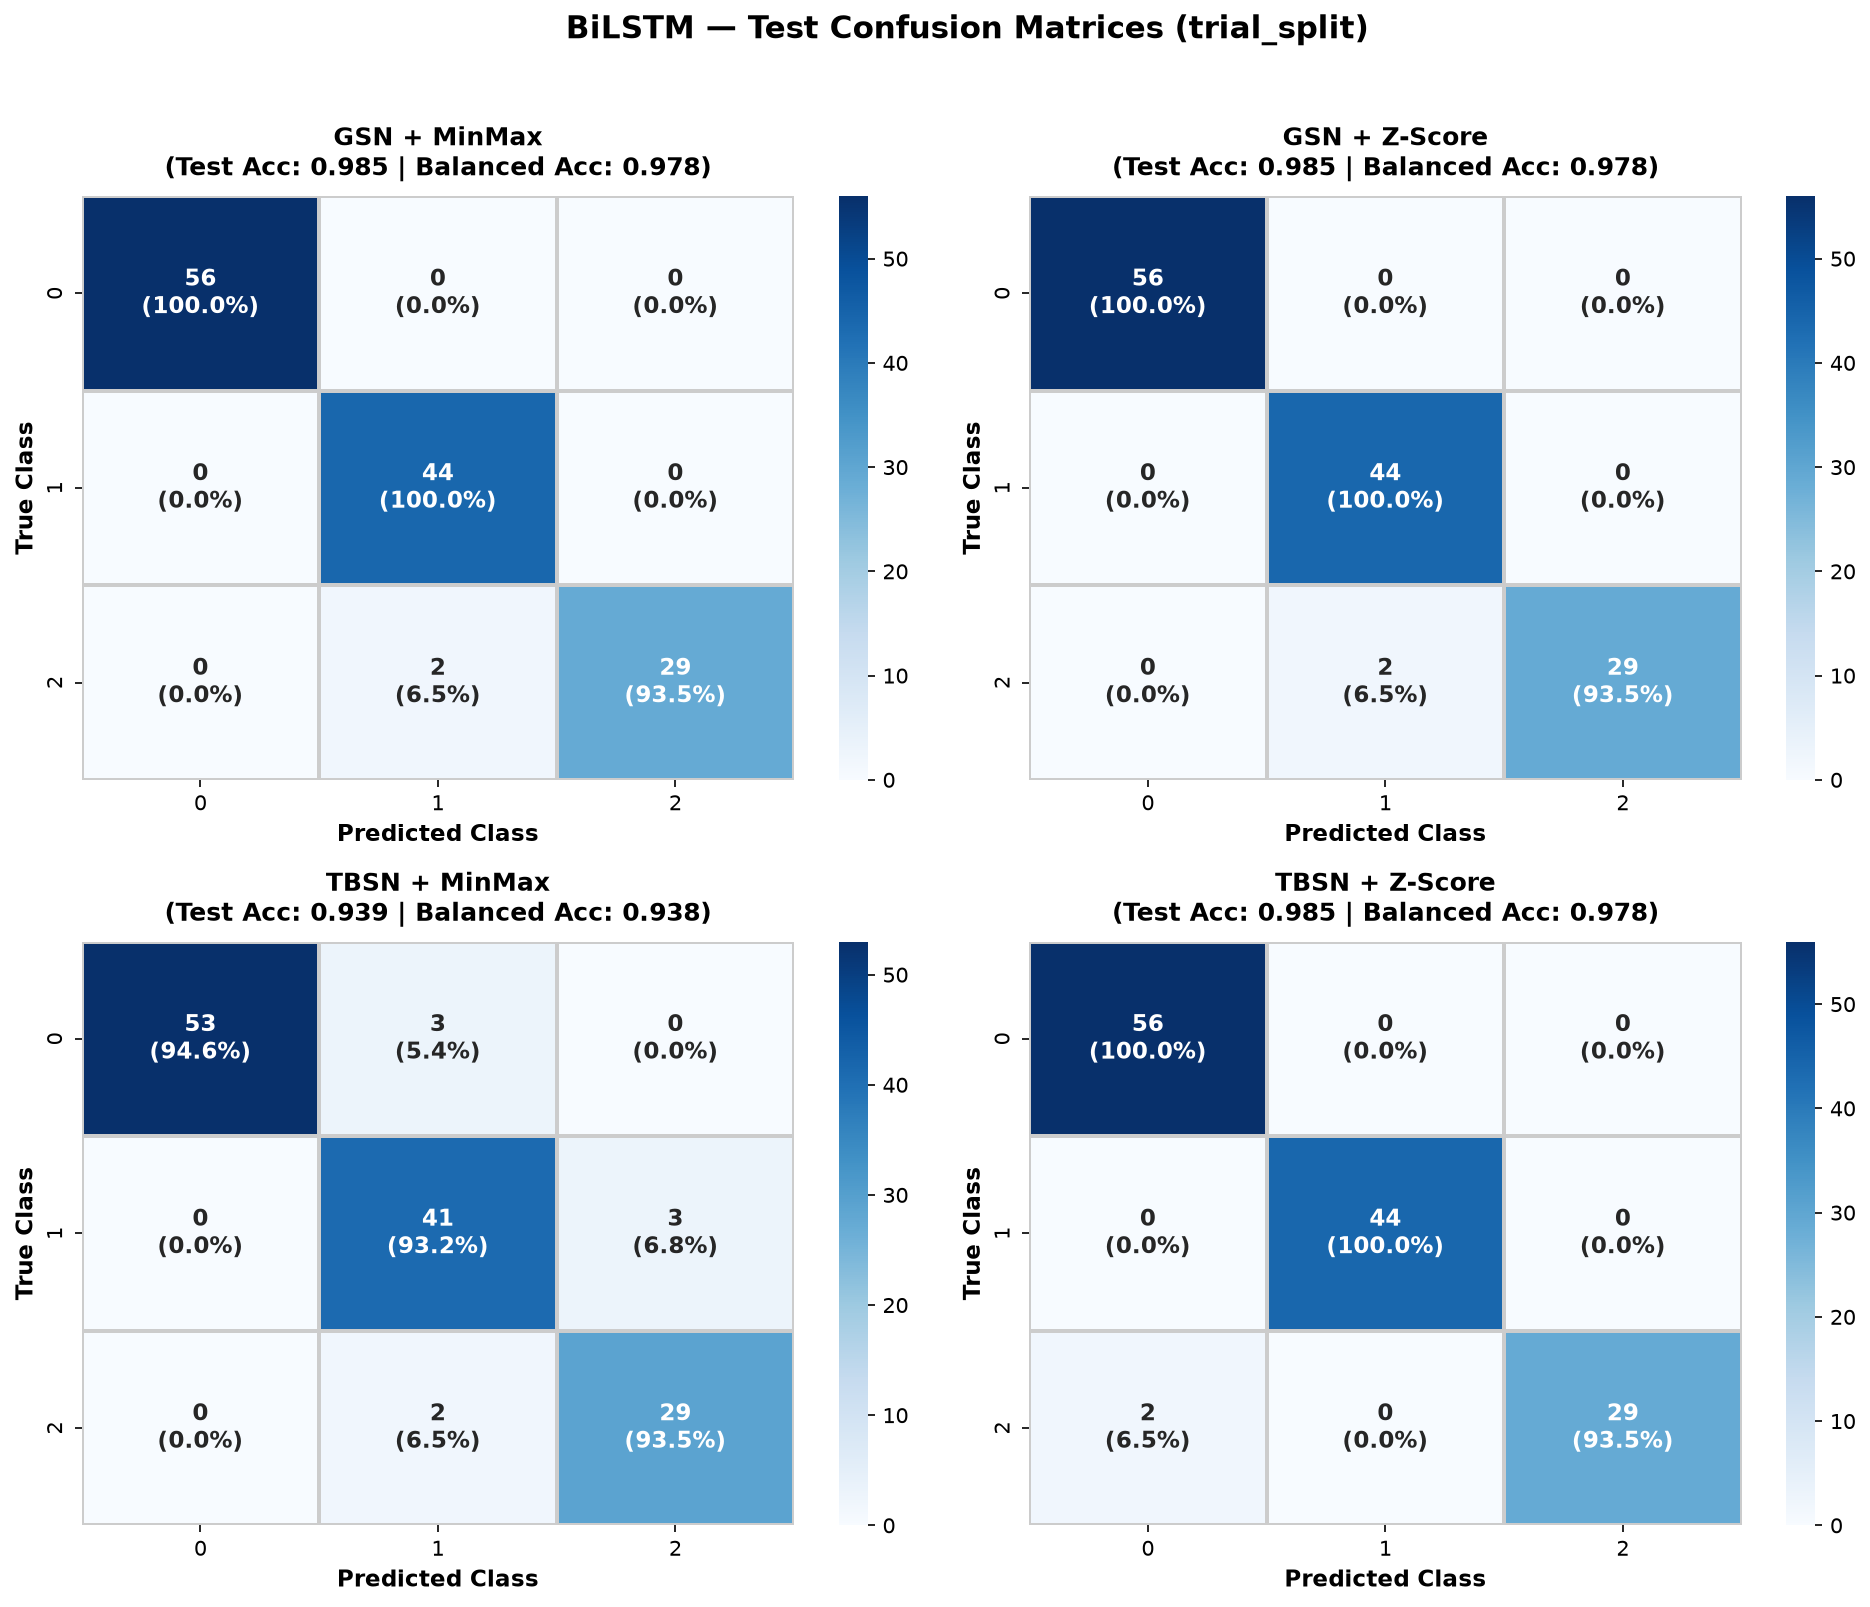

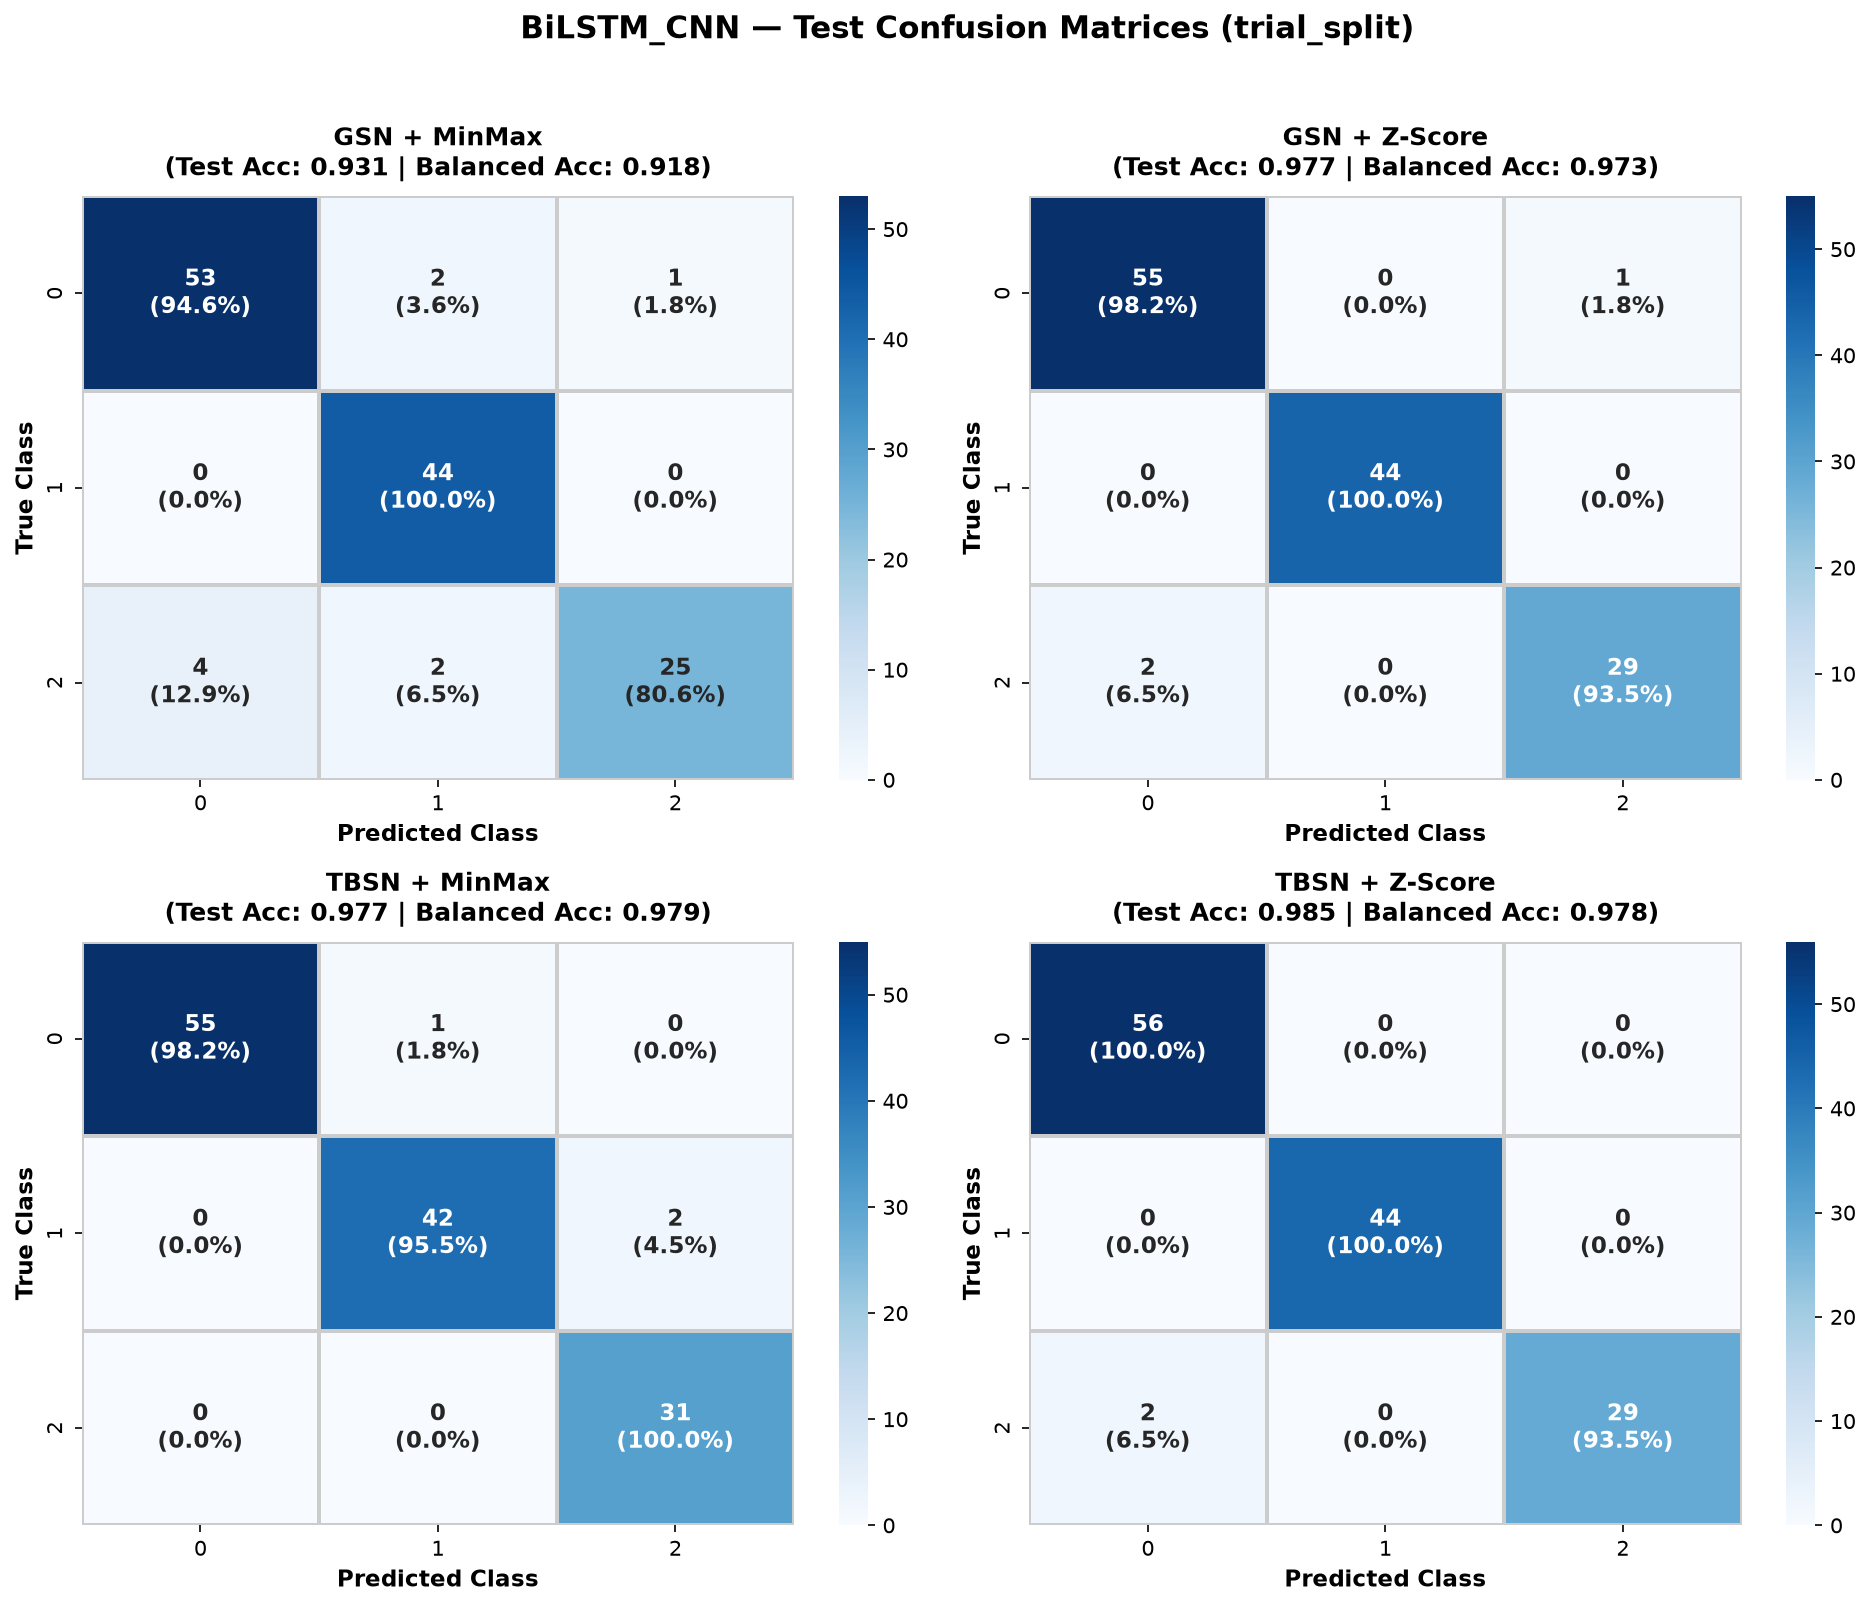

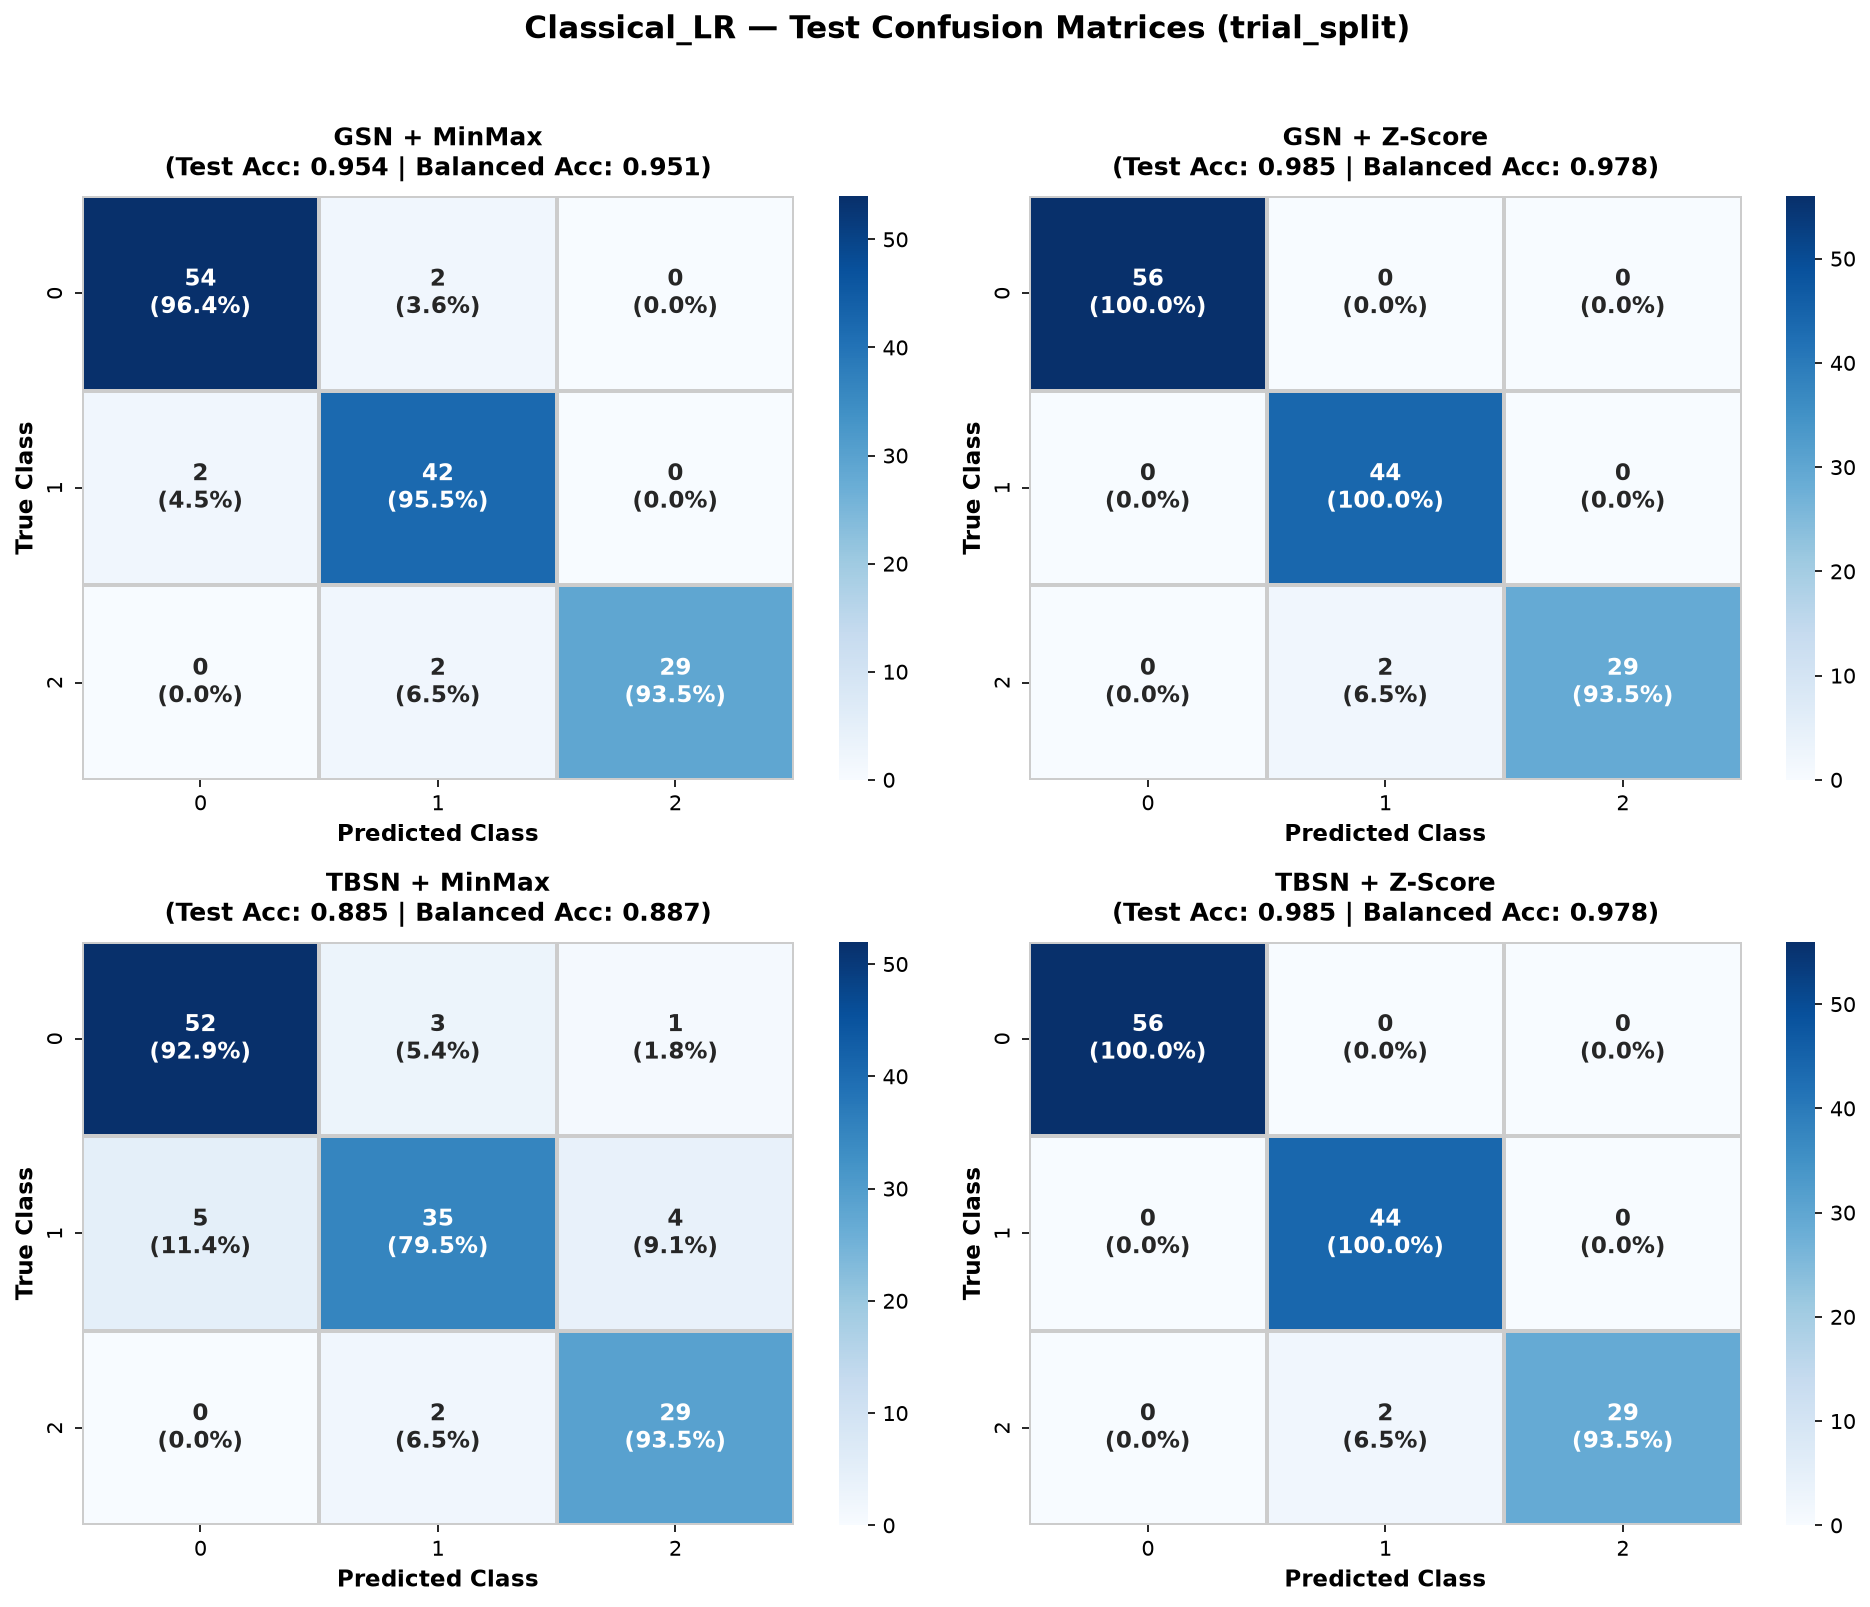

In [5]:
# ============================================================================
# CELL 5: FIGURE TYPE 3 — CONFUSION MATRICES (ALL 5 MODELS x 4 BRANCHES)
# ============================================================================
cm_figures_generated = []

for model in ALL_MODELS:
    fig, axes = plt.subplots(2, 2, figsize=(13, 11))
    axes_flat = axes.flatten()
    
    for idx, branch in enumerate(BRANCHES):
        ax = axes_flat[idx]
        sub_preds = df_preds[(df_preds['model'] == model) & (df_preds['branch'] == branch)]
        
        # Calculate confusion matrix for classes [0, 1, 2]
        cm = confusion_matrix(sub_preds['true_label'], sub_preds['pred_label'], labels=CLASS_LABELS)
        assert cm.sum() == len(sub_preds) == 131, f"Count mismatch in {model} {branch}: {cm.sum()}"
        
        row_sums = cm.sum(axis=1, keepdims=True)
        cm_norm = np.divide(cm.astype('float'), row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0)
        
        # Cell text annotation: count + row percentage
        annot_matrix = np.empty_like(cm, dtype=object)
        for r in range(3):
            for c in range(3):
                cnt = cm[r, c]
                pct = cm_norm[r, c] * 100.0
                annot_matrix[r, c] = f"{cnt}\n({pct:.1f}%)"
                
        metrics_sub = df_metrics[(df_metrics['model'] == model) & (df_metrics['branch'] == branch)]
        test_acc  = float(metrics_sub['test_accuracy'].values[0])
        test_bacc = float(metrics_sub['test_balanced_accuracy'].values[0])
        
        sns.heatmap(
            cm, annot=annot_matrix, fmt="", cmap="Blues",
            cbar=True, ax=ax,
            xticklabels=['0', '1', '2'],
            yticklabels=['0', '1', '2'],
            annot_kws={'fontsize': 11, 'fontweight': 'bold'},
            linewidths=1.0, linecolor='#cccccc'
        )
        
        ax.set_title(
            f"{BRANCH_TITLES[branch]}\n(Test Acc: {test_acc:.3f} | Balanced Acc: {test_bacc:.3f})",
            fontsize=12, fontweight='bold', pad=10
        )
        ax.set_xlabel('Predicted Class', fontsize=11, fontweight='bold')
        ax.set_ylabel('True Class', fontsize=11, fontweight='bold')
        
    fig.suptitle(f"{model} — Test Confusion Matrices (trial_split)", fontsize=15, fontweight='bold', y=0.99)
    plt.tight_layout(rect=[0, 0.02, 1, 0.97])
    
    png_path = FIGURES_DIR / f"{model}_confusion_matrices.png"
    pdf_path = FIGURES_DIR / f"{model}_confusion_matrices.pdf"
    plt.savefig(png_path, dpi=300, bbox_inches='tight')
    plt.savefig(pdf_path, bbox_inches='tight')
    plt.show() # Display inline in notebook
    plt.close(fig)
    
    cm_figures_generated.append((model, png_path, pdf_path))
    print(f"Generated Confusion Matrix Figure: {png_path.name} | {pdf_path.name}")

print(f"\n[SUCCESS] Completed {len(cm_figures_generated)} Confusion matrix figures (PNG and PDF).")

---
## 6. Plotting Data & Confusion Matrix Counts Export

Export cleaned CSV tables containing the exact plotted values (epoch-by-epoch curves and cell-by-cell confusion matrix counts) to `figures/model/baseline_metric_visualizations/` for reproducibility.

In [6]:
# ============================================================================
# CELL 6: EXPORT CLEANED PLOTTING DATA TO REPRODUCIBLE CSVS
# ============================================================================
# 1. Loss Curves Table
loss_export_cols = ['model', 'branch', 'fold', 'run_id', 'epoch', 'train_loss', 'val_loss', 'is_best']
df_loss_export = df_history[loss_export_cols].copy()
loss_csv_path = FIGURES_DIR / 'training_validation_loss_curves.csv'
df_loss_export.to_csv(loss_csv_path, index=False)
print(f"Saved: {loss_csv_path.name} ({len(df_loss_export)} rows)")

# 2. Accuracy Curves Table
acc_export_cols = ['model', 'branch', 'fold', 'run_id', 'epoch', 'train_accuracy', 'val_accuracy', 'is_best']
df_acc_export = df_history[acc_export_cols].copy()
acc_csv_path = FIGURES_DIR / 'training_validation_accuracy_curves.csv'
df_acc_export.to_csv(acc_csv_path, index=False)
print(f"Saved: {acc_csv_path.name} ({len(df_acc_export)} rows)")

# 3. Confusion Matrix Counts Table
cm_records = []
for model in ALL_MODELS:
    for branch in BRANCHES:
        sub_preds = df_preds[(df_preds['model'] == model) & (df_preds['branch'] == branch)]
        cm = confusion_matrix(sub_preds['true_label'], sub_preds['pred_label'], labels=CLASS_LABELS)
        row_sums = cm.sum(axis=1)
        run_id_val = sub_preds['run_id'].values[0]
        
        for r in range(3):
            for c in range(3):
                cnt = int(cm[r, c])
                r_tot = int(row_sums[r])
                pct = float((cnt / r_tot * 100.0) if r_tot > 0 else 0.0)
                cm_records.append({
                    'model': model,
                    'branch': branch,
                    'fold': 'trial_split',
                    'run_id': run_id_val,
                    'true_class': r,
                    'pred_class': c,
                    'count': cnt,
                    'row_total': r_tot,
                    'row_percentage': round(pct, 2)
                })

df_cm_export = pd.DataFrame(cm_records)
cm_csv_path = FIGURES_DIR / 'confusion_matrix_counts.csv'
df_cm_export.to_csv(cm_csv_path, index=False)
print(f"Saved: {cm_csv_path.name} ({len(df_cm_export)} rows: 5 models x 4 branches x 9 cells)")

# 4. Baseline Evaluation Summary Table
summary_cols = [
    'model', 'branch', 'fold', 'run_id', 'n_train', 'n_val', 'n_test',
    'epochs_executed', 'best_epoch', 'best_val_loss', 'best_val_accuracy',
    'test_accuracy', 'test_balanced_accuracy', 'test_macro_f1', 'test_weighted_f1', 'cohen_kappa', 'mae'
]
df_summary_export = df_metrics[[c for c in summary_cols if c in df_metrics.columns]].copy()
summary_csv_path = FIGURES_DIR / 'baseline_test_evaluation_summary.csv'
df_summary_export.to_csv(summary_csv_path, index=False)
print(f"Saved: {summary_csv_path.name} ({len(df_summary_export)} rows)")

Saved: training_validation_loss_curves.csv (789 rows)
Saved: training_validation_accuracy_curves.csv (789 rows)
Saved: confusion_matrix_counts.csv (180 rows: 5 models x 4 branches x 9 cells)
Saved: baseline_test_evaluation_summary.csv (20 rows)


---
## 7. Quality Assurance and Completion Audit

Verify that all required files were generated on disk with non-zero byte size, that confusion matrix cell counts reconcile with predictions, and display the final completion summary.

In [7]:
# ============================================================================
# CELL 7: FINAL VALIDATION AND COMPLETION AUDIT
# ============================================================================
print("=" * 80)
print("NOTEBOOK 11A — BASELINE METRIC VISUALIZATION AUDIT")
print("=" * 80)

# 1. Expected Artifact Verification
expected_figures = []
for m in DEEP_MODELS:
    expected_figures.extend([
        f"{m}_training_validation_loss.png", f"{m}_training_validation_loss.pdf",
        f"{m}_training_validation_accuracy.png", f"{m}_training_validation_accuracy.pdf"
    ])
for m in ALL_MODELS:
    expected_figures.extend([
        f"{m}_confusion_matrices.png", f"{m}_confusion_matrices.pdf"
    ])

expected_csvs = [
    'training_validation_loss_curves.csv',
    'training_validation_accuracy_curves.csv',
    'confusion_matrix_counts.csv',
    'baseline_test_evaluation_summary.csv'
]

missing_artifacts = []
file_audit_rows = []

for fname in expected_figures + expected_csvs:
    fpath = FIGURES_DIR / fname
    if not fpath.exists():
        missing_artifacts.append(f"{fname} (Missing)")
        file_audit_rows.append({'file': fname, 'status': 'MISSING', 'bytes': 0})
    elif fpath.stat().st_size == 0:
        missing_artifacts.append(f"{fname} (Zero bytes)")
        file_audit_rows.append({'file': fname, 'status': 'EMPTY', 'bytes': 0})
    else:
        file_audit_rows.append({'file': fname, 'status': 'OK', 'bytes': fpath.stat().st_size})

df_file_audit = pd.DataFrame(file_audit_rows)

# 2. Confusion Matrix Count Reconciliation
cm_recon_errors = []
for model in ALL_MODELS:
    for branch in BRANCHES:
        sub_cm = df_cm_export[(df_cm_export['model'] == model) & (df_cm_export['branch'] == branch)]
        cell_sum = sub_cm['count'].sum()
        pred_count = len(df_preds[(df_preds['model'] == model) & (df_preds['branch'] == branch)])
        if cell_sum != pred_count or cell_sum != 131:
            cm_recon_errors.append(f"{model} {branch}: CM sum {cell_sum} != Pred count {pred_count}")

# 3. Summary Report
print(f"Models successfully plotted         : {ALL_MODELS} (5 models)")
print(f"Deep models (Loss + Acc curves)     : {DEEP_MODELS} (4 models)")
print(f"Branches represented                : {BRANCHES} (4 branches)")
print(f"Figures generated                   : {len(expected_figures)} (13 PNGs @ 300 DPI + 13 PDFs)")
print(f"Data CSVs generated                 : {len(expected_csvs)}")
print(f"Output Directory                    : {FIGURES_DIR}")

print("\nSaved File Artifacts Inventory:")
print(f"{'Filename':<46} | {'Status':<8} | {'Size (KB)':<10}")
print("-" * 72)
for _, r in df_file_audit.iterrows():
    print(f"{r['file']:<46} | {r['status']:<8} | {r['bytes']/1024:8.2f} KB")

# 4. Final Quality Gate
print("\n" + "=" * 80)
if len(missing_artifacts) == 0 and len(cm_recon_errors) == 0:
    print("ALL VALIDATION CHECKS PASSED: 100% COMPLETE")
    print(f"All 26 publication figures and 4 data CSVs verified on disk.")
    print("=" * 80)
else:
    print("VALIDATION FAILURES DETECTED:")
    for err in missing_artifacts + cm_recon_errors:
        print(f"  - {err}")
    print("=" * 80)
    raise RuntimeError("Notebook 11A validation audit failed.")

NOTEBOOK 11A — BASELINE METRIC VISUALIZATION AUDIT
Models successfully plotted         : ['CNN1D', 'LSTM', 'BiLSTM', 'BiLSTM_CNN', 'Classical_LR'] (5 models)
Deep models (Loss + Acc curves)     : ['CNN1D', 'LSTM', 'BiLSTM', 'BiLSTM_CNN'] (4 models)
Branches represented                : ['gsn_minmax', 'gsn_zscore', 'tbsn_minmax', 'tbsn_zscore'] (4 branches)
Figures generated                   : 26 (13 PNGs @ 300 DPI + 13 PDFs)
Data CSVs generated                 : 4
Output Directory                    : C:\Users\lab\Minor_project\Parkinson_gait\figures\model\baseline_metric_visualizations

Saved File Artifacts Inventory:
Filename                                       | Status   | Size (KB) 
------------------------------------------------------------------------
CNN1D_training_validation_loss.png             | OK       |   696.11 KB
CNN1D_training_validation_loss.pdf             | OK       |    32.49 KB
CNN1D_training_validation_accuracy.png         | OK       |   536.73 KB
CNN1D_traini